# Retail Analytics Copilot: Olist Brazilian E-commerce

**Ayush Jain** · M.E. Computer Science, BITS Pilani Goa

An end-to-end analytics project on ~99k real marketplace orders (Sep 2016 – Oct 2018), built to cover
the full data-science workflow: SQL, customer segmentation, a leakage-free predictive model, model
explainability, hypothesis testing, experiment design, and a GenAI text-to-SQL agent.

| Part | Business question | Methods |
|---|---|---|
| 1 | How is the business doing, and who are the customers? | SQLite, CTEs, window functions, RFM + K-Means |
| 2 | Can we predict a late delivery at the moment the order is placed? | Logistic Regression, Random Forest, Gradient Boosting, time-based validation |
| 3 | Why does the model flag an order? | Permutation importance, partial dependence, LR coefficients, linear SHAP |
| 4 | Do late deliveries hurt reviews? How big must a retention A/B test be? | Mann-Whitney U, Welch t-test, chi-square, Mantel-Haenszel, power analysis |
| 5 | Can a manager ask questions in plain English? | LLM text-to-SQL agent on Groq with read-only guardrails (`agent/sql_agent.py`) |
| 6 | What should the business do? | Recommendations with estimated impact |

**Data:** the public [Olist dataset on Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce): 9 CSVs, unzipped into `data/`.

## 0. Setup

In [1]:
import os
import sys
import json
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve,
                             silhouette_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from build_db import build_database   # loads the 9 CSVs into SQLite (shared with the agent)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

RANDOM_STATE = 42
DATA_DIR = Path("data")          # the 9 Olist CSVs
DB_PATH = Path("olist.db")       # SQLite database built from them
FIG_DIR = Path("figures")        # charts reused in the report
RESULTS_PATH = Path("results/summary.json")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_PATH.parent.mkdir(exist_ok=True)
results = {}                     # key numbers, saved at the end for the report

# One chart style for the whole notebook: thin marks, light grid, colour-blind-safe palette order
BLUE, ORANGE, AQUA, RED, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#a3a29c"
INK, INK_2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "figure.figsize": (9, 4),
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "font.size": 10, "legend.frameon": False,
})


def fmt_p(p: float) -> str:
    """p-values this small underflow to 0.0 in floating point; report them as a bound instead."""
    return "< 1e-300" if p == 0 else f"= {p:.2e}"


def save(fig, name):
    """Save a chart into figures/ so the report can reuse it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")


pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:,.2f}".format)
print("pandas", pd.__version__, "| numpy", np.__version__, "| python", sys.version.split()[0])

pandas 3.0.5 | numpy 2.5.3 | python 3.13.16


## Part 1. SQL analysis in SQLite

### 1.0 Load the CSVs into SQLite
`build_db.py` reads each CSV (keeping zip codes as text so leading zeros survive), writes it as a table,
adds indexes on the join keys and creates one view, `v_order_delivery`, which holds **the** definition of
delivery time and lateness used everywhere in this project (and by the agent):

- `delivery_days` = delivered date − purchase timestamp
- `promised_days` = estimated delivery date − purchase timestamp (the date Olist shows the customer)
- `is_late` = delivered **calendar date** > estimated **calendar date** (the estimate has no time of day,
  so arriving at 3 pm on the promised day counts as on time)

In [2]:
build_database(DATA_DIR, DB_PATH)        # rebuilds from scratch, ~5 seconds
con = sqlite3.connect(DB_PATH)


def sql(query: str) -> pd.DataFrame:
    """Run a SQL query against olist.db and return a DataFrame."""
    return pd.read_sql_query(query, con)


sql("""
SELECT name, type
FROM sqlite_master
WHERE type IN ('table', 'view') AND name NOT LIKE 'sqlite_%'
ORDER BY type, name
""")

  loaded orders                    99,441 rows
  loaded order_items              112,650 rows
  loaded customers                 99,441 rows
  loaded payments                 103,886 rows
  loaded reviews                   99,224 rows
  loaded products                  32,951 rows
  loaded sellers                    3,095 rows
  loaded category_translation          71 rows
  loaded geolocation            1,000,163 rows
Built olist.db (169 MB) in 5.3s


,name,type
0,category_translation,table
1,customers,table
2,geolocation,table
3,order_items,table
4,orders,table
5,payments,table
6,products,table
7,reviews,table
8,sellers,table
9,v_order_delivery,view


### 1.1 Data-quality checks before any analysis
Three traps in this dataset that change answers if you miss them:
1. **`customer_id` is a new id per order.** The real person is `customer_unique_id`. Counting `customer_id`
   makes every customer look like a one-time buyer by construction.
2. **Some orders have more than one review**, so joining reviews to orders can double-count.
3. **The edges of the date range are thin** (Sep–Dec 2016, Sep–Oct 2018), so trends use Jan 2017 – Aug 2018.

In [3]:
dq = sql("""
SELECT
    (SELECT MIN(order_purchase_timestamp) FROM orders)                       AS first_order,
    (SELECT MAX(order_purchase_timestamp) FROM orders)                       AS last_order,
    (SELECT COUNT(*) FROM orders)                                            AS orders,
    (SELECT COUNT(*) FROM customers)                                         AS customer_ids,
    (SELECT COUNT(DISTINCT customer_unique_id) FROM customers)               AS unique_customers,
    (SELECT COUNT(*) - COUNT(DISTINCT order_id) FROM reviews)                AS extra_review_rows,
    (SELECT COUNT(*) FROM orders WHERE order_status = 'delivered'
                                   AND order_delivered_customer_date IS NULL) AS delivered_without_date,
    (SELECT COUNT(*) FROM products WHERE product_category_name IS NULL)      AS products_without_category
""").T.rename(columns={0: "value"})
dq

,value
first_order,2016-09-04 21:15:19
last_order,2018-10-17 17:30:18
orders,99441
customer_ids,99441
unique_customers,96096
extra_review_rows,551
delivered_without_date,8
products_without_category,610


In [4]:
# Order status mix: almost everything is delivered, so delivery is the core customer experience
sql("""
SELECT order_status,
       COUNT(*)                                           AS orders,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
FROM orders
GROUP BY order_status
ORDER BY orders DESC
""")

,order_status,orders,pct
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00


### 1.2 Monthly revenue
**GMV** = item price + freight, for orders that weren't canceled or unavailable. The query uses a CTE to roll
items up to orders, then the `LAG` window function for month-over-month growth.

In [5]:
monthly = sql("""
WITH order_value AS (                         -- one row per order
    SELECT o.order_id,
           strftime('%Y-%m', o.order_purchase_timestamp) AS month,
           SUM(oi.price)                                 AS product_revenue,
           SUM(oi.freight_value)                         AS freight
    FROM orders o
    JOIN order_items oi ON oi.order_id = o.order_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
    GROUP BY o.order_id
),
by_month AS (
    SELECT month,
           COUNT(*)                         AS orders,
           SUM(product_revenue + freight)   AS gmv,
           SUM(product_revenue)             AS product_revenue
    FROM order_value
    WHERE month BETWEEN '2017-01' AND '2018-08'   -- complete months only
    GROUP BY month
)
SELECT month,
       orders,
       ROUND(gmv, 0)                                                    AS gmv,
       ROUND(gmv / orders, 2)                                           AS avg_order_value,
       ROUND(100.0 * (gmv - LAG(gmv) OVER (ORDER BY month))
                   / LAG(gmv) OVER (ORDER BY month), 1)                 AS mom_growth_pct
FROM by_month
ORDER BY month
""")
monthly

,month,orders,gmv,avg_order_value,mom_growth_pct
0,2017-01,787,"136,943.00",174.01,NaN
1,2017-02,1718,"283,562.00",165.05,107.10
2,2017-03,2617,"425,618.00",162.64,50.10
3,2017-04,2377,"405,849.00",170.74,-4.60
4,2017-05,3640,"582,711.00",160.09,43.60
5,2017-06,3205,"499,652.00",155.90,-14.30
6,2017-07,3946,"578,754.00",146.67,15.80
7,2017-08,4272,"661,904.00",154.94,14.40
8,2017-09,4227,"717,103.00",169.65,8.30
9,2017-10,4547,"764,756.00",168.19,6.60


In [6]:
# Year-over-year: compare the same months (Jan-Aug) of 2017 and 2018
monthly["year"] = monthly["month"].str[:4]
jan_aug = monthly[monthly["month"].str[5:] <= "08"].groupby("year")[["orders", "gmv"]].sum()
yoy_gmv = jan_aug.loc["2018", "gmv"] / jan_aug.loc["2017", "gmv"] - 1
yoy_orders = jan_aug.loc["2018", "orders"] / jan_aug.loc["2017", "orders"] - 1
peak = monthly.loc[monthly["gmv"].idxmax()]
print(f"Jan-Aug GMV: 2017 = R${jan_aug.loc['2017','gmv']:,.0f} | 2018 = R${jan_aug.loc['2018','gmv']:,.0f} "
      f"| growth = {yoy_gmv:.0%} (orders {yoy_orders:.0%})")
print(f"Peak month: {peak['month']} with GMV R${peak['gmv']:,.0f} ({peak['orders']:,} orders)")
print(f"Average order value across the period: R${monthly['gmv'].sum() / monthly['orders'].sum():,.2f}")
results["revenue"] = {"jan_aug_2017_gmv": float(jan_aug.loc["2017", "gmv"]),
                      "jan_aug_2018_gmv": float(jan_aug.loc["2018", "gmv"]),
                      "yoy_gmv_growth": float(yoy_gmv), "yoy_order_growth": float(yoy_orders),
                      "peak_month": peak["month"], "peak_gmv": float(peak["gmv"]),
                      "aov": float(monthly["gmv"].sum() / monthly["orders"].sum())}

Jan-Aug GMV: 2017 = R$3,574,993 | 2018 = R$8,593,138 | growth = 140% (orders 137%)
Peak month: 2017-11 with GMV R$1,172,192 (7,421 orders)
Average order value across the period: R$160.19


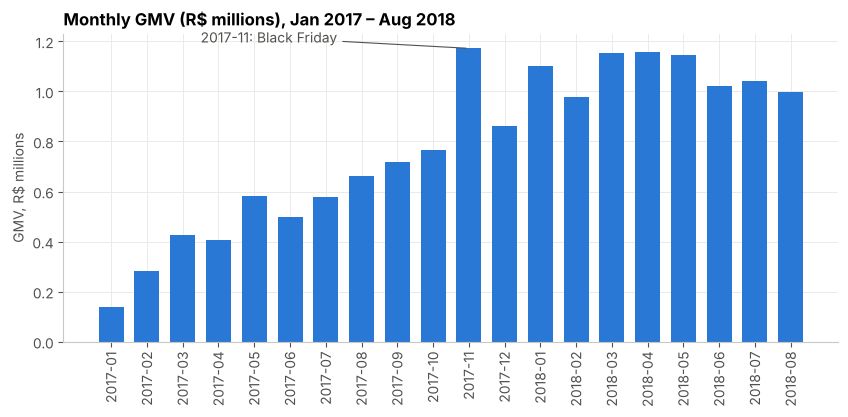

In [7]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly["month"], monthly["gmv"] / 1e6, color=BLUE, width=0.7)
ax.set_title("Monthly GMV (R$ millions), Jan 2017 – Aug 2018")
ax.set_ylabel("GMV, R$ millions")
ax.tick_params(axis="x", rotation=90)
i = monthly["gmv"].idxmax()
ax.annotate(f"{monthly.loc[i, 'month']}: Black Friday", xy=(i, monthly.loc[i, "gmv"] / 1e6),
            xytext=(i - 7.5, monthly.loc[i, "gmv"] / 1e6 * 1.02), color=INK_2,
            arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8))
save(fig, "01_monthly_gmv")
plt.show()

### 1.3 Top product categories
Revenue here is item price only (freight excluded). Category names are Portuguese in `products`, so the query
joins the translation table and falls back to the Portuguese name when a translation is missing. The average
review per category comes from a CTE that first averages reviews per order (trap 2 above).

In [8]:
categories = sql("""
WITH order_review AS (                       -- one review score per order
    SELECT order_id, AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
),
valid_items AS (
    SELECT oi.*
    FROM order_items oi
    JOIN orders o ON o.order_id = oi.order_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
)
SELECT COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category,
       COUNT(DISTINCT vi.order_id)                                      AS orders,
       ROUND(SUM(vi.price), 0)                                          AS revenue,
       ROUND(100.0 * SUM(vi.price) / (SELECT SUM(price) FROM valid_items), 1) AS revenue_share_pct,
       ROUND(AVG(vi.price), 2)                                          AS avg_item_price,
       ROUND(AVG(r.review_score), 2)                                    AS avg_review
FROM valid_items vi
LEFT JOIN products p             ON p.product_id = vi.product_id
LEFT JOIN category_translation t ON t.product_category_name = p.product_category_name
LEFT JOIN order_review r         ON r.order_id = vi.order_id
GROUP BY category
ORDER BY revenue DESC
""")
top10 = categories.head(10)
print(f"{len(categories)} categories; the top 10 earn {top10['revenue_share_pct'].sum():.1f}% of product revenue")
top10

74 categories; the top 10 earn 62.4% of product revenue


,category,orders,revenue,revenue_share_pct,avg_item_price,avg_review
0,health_beauty,8800,"1,255,695.00",9.30,130.34,4.15
1,watches_gifts,5604,"1,198,185.00",8.90,200.70,4.03
2,bed_bath_table,9399,"1,035,964.00",7.70,93.36,3.90
3,sports_leisure,7673,"979,741.00",7.30,114.06,4.12
4,computers_accessories,6654,"904,322.00",6.70,116.22,3.95
5,furniture_decor,6425,"727,465.00",5.40,87.67,3.92
6,housewares,5847,"626,826.00",4.60,90.65,4.07
7,cool_stuff,3616,"620,770.00",4.60,164.27,4.16
8,auto,3872,"586,586.00",4.30,139.53,4.08
9,garden_tools,3505,"481,010.00",3.60,111.14,4.06


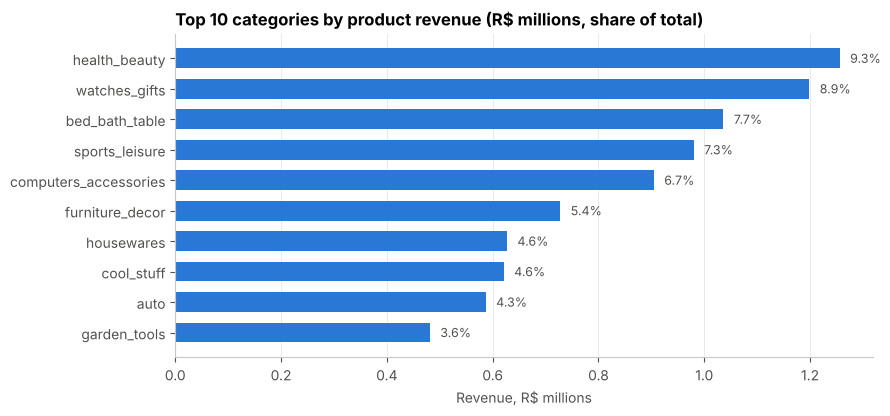

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2))
d = top10.iloc[::-1]
ax.barh(d["category"], d["revenue"] / 1e6, color=BLUE, height=0.65)
for y, (v, s) in enumerate(zip(d["revenue"] / 1e6, d["revenue_share_pct"])):
    ax.text(v + 0.02, y, f"{s:.1f}%", va="center", color=INK_2, fontsize=9)
ax.set_title("Top 10 categories by product revenue (R$ millions, share of total)")
ax.set_xlabel("Revenue, R$ millions")
ax.grid(axis="y", visible=False)
save(fig, "02_top_categories")
plt.show()

### 1.4 Delivery time by customer state
Uses the `v_order_delivery` view. `promised_days` is what the customer was shown; `delivery_days` is what happened.

In [10]:
delivery_by_state = sql("""
SELECT customer_state                       AS state,
       COUNT(*)                             AS delivered_orders,
       ROUND(AVG(delivery_days), 1)         AS avg_delivery_days,
       ROUND(AVG(promised_days), 1)         AS avg_promised_days,
       ROUND(100.0 * AVG(is_late), 1)       AS late_pct
FROM v_order_delivery
GROUP BY customer_state
ORDER BY avg_delivery_days DESC
""")
national = sql("""
SELECT COUNT(*) AS delivered_orders,
       ROUND(AVG(delivery_days), 1)   AS avg_delivery_days,
       ROUND(AVG(promised_days), 1)   AS avg_promised_days,
       ROUND(100.0 * AVG(is_late), 2) AS late_pct
FROM v_order_delivery
""")
display(national)
delivery_by_state

,delivered_orders,avg_delivery_days,avg_promised_days,late_pct
0,96470,12.60,23.70,6.77


,state,delivered_orders,avg_delivery_days,avg_promised_days,late_pct
0,RR,41,29.40,46.00,12.20
1,AP,67,27.20,46.20,3.00
2,AM,145,26.40,45.30,2.80
3,AL,397,24.50,32.60,21.40
4,PA,946,23.80,37.20,11.20
5,MA,717,21.60,30.50,17.40
6,SE,335,21.50,30.80,15.20
7,CE,1279,21.30,31.40,13.80
8,AC,80,21.00,41.10,3.80
9,PB,517,20.40,33.00,10.40


In [11]:
nat = national.iloc[0]
fast, slow = delivery_by_state.iloc[-1], delivery_by_state.iloc[0]
print(f"Nationally: delivered in {nat['avg_delivery_days']} days on average vs {nat['avg_promised_days']} promised; "
      f"{nat['late_pct']}% arrive late.")
print(f"Fastest state: {fast['state']} ({fast['avg_delivery_days']} days). "
      f"Slowest: {slow['state']} ({slow['avg_delivery_days']} days, {slow['late_pct']}% late).")
big = delivery_by_state[delivery_by_state["delivered_orders"] >= 1000].sort_values("late_pct", ascending=False)
print("Highest late rate among states with 1,000+ orders:",
      ", ".join(f"{r.state} {r.late_pct}%" for r in big.head(3).itertuples()))
results["delivery"] = {"avg_delivery_days": float(nat["avg_delivery_days"]),
                       "avg_promised_days": float(nat["avg_promised_days"]),
                       "late_pct": float(nat["late_pct"]), "delivered_orders": int(nat["delivered_orders"]),
                       "fastest_state": fast["state"], "fastest_days": float(fast["avg_delivery_days"]),
                       "slowest_state": slow["state"], "slowest_days": float(slow["avg_delivery_days"]),
                       "worst_late_states_1000plus": big.head(3)[["state", "late_pct"]].to_dict("records")}

Nationally: delivered in 12.6 days on average vs 23.7 promised; 6.77% arrive late.
Fastest state: SP (8.8 days). Slowest: RR (29.4 days, 12.2% late).
Highest late rate among states with 1,000+ orders: CE 13.8%, BA 12.2%, RJ 12.1%


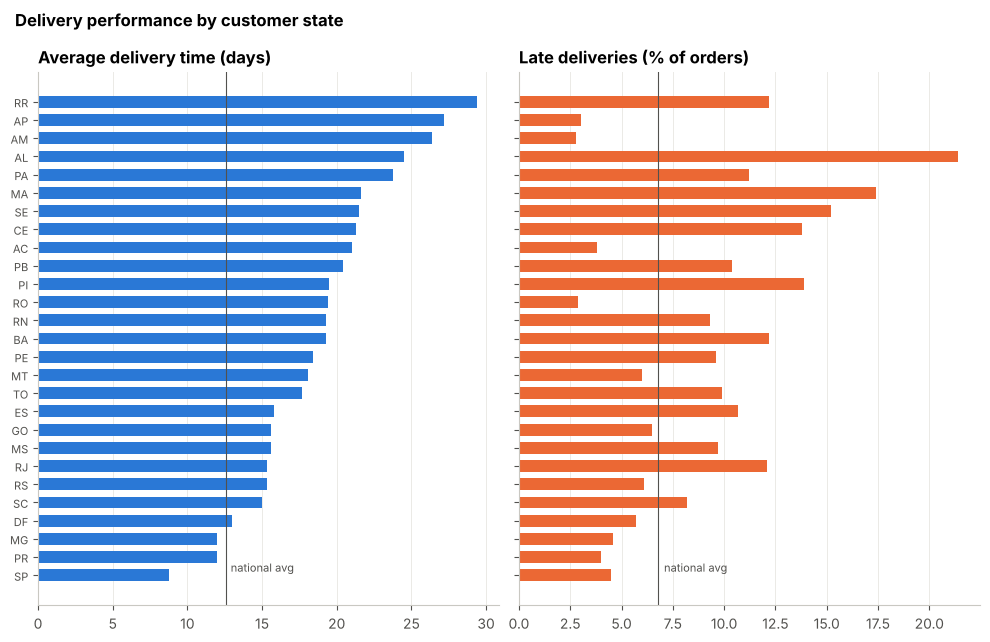

In [12]:
# Two panels with the same state order (no dual axis): how long delivery takes, and how often it's late
d = delivery_by_state.sort_values("avg_delivery_days")
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 6.5), sharey=True)
a1.barh(d["state"], d["avg_delivery_days"], color=BLUE, height=0.65)
a1.axvline(nat["avg_delivery_days"], color=INK_2, lw=0.8)
a1.text(nat["avg_delivery_days"] + 0.3, 0.2, "national avg", color=INK_2, fontsize=8)
a1.set_title("Average delivery time (days)")
a2.barh(d["state"], d["late_pct"], color=ORANGE, height=0.65)
a2.axvline(nat["late_pct"], color=INK_2, lw=0.8)
a2.text(nat["late_pct"] + 0.3, 0.2, "national avg", color=INK_2, fontsize=8)
a2.set_title("Late deliveries (% of orders)")
for a in (a1, a2):
    a.grid(axis="y", visible=False)
a1.tick_params(axis="y", labelsize=8)
fig.suptitle("Delivery performance by customer state", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "03_delivery_by_state")
plt.show()

### 1.5 How often do customers come back?
This is where trap 1 matters. Counting `customer_id` says nobody ever returns; counting `customer_unique_id`
gives the true (still very low) repeat rate.

In [13]:
repeat = sql("""
WITH per_customer AS (
    SELECT c.customer_unique_id,
           COUNT(DISTINCT o.order_id) AS n_orders
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.order_status NOT IN ('canceled', 'unavailable')
    GROUP BY c.customer_unique_id
)
SELECT CASE WHEN n_orders >= 4 THEN '4+' ELSE CAST(n_orders AS TEXT) END AS orders_per_customer,
       COUNT(*)                                                         AS customers,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2)               AS pct_customers
FROM per_customer
GROUP BY orders_per_customer
ORDER BY orders_per_customer
""")
repeat_rate = 100 - repeat.loc[repeat["orders_per_customer"] == "1", "pct_customers"].iloc[0]
print(f"Only {repeat_rate:.2f}% of customers ever placed a second order.")
results["customers"] = {"unique_customers": int(repeat["customers"].sum()), "repeat_pct": float(repeat_rate)}
repeat

Only 3.04% of customers ever placed a second order.


,orders_per_customer,customers,pct_customers
0,1,92102,96.96
1,2,2652,2.79
2,3,188,0.20
3,4+,48,0.05


### 1.6 RFM segmentation with K-Means
For each person (`customer_unique_id`):
- **Recency**: days since their last order, measured from the day after the last order in the data
- **Frequency**: number of orders
- **Monetary**: total spend (items + freight)

**Why transform first:** spend is heavily right-skewed and K-Means uses Euclidean distance, so a few big spenders
would dominate. I take `log1p` of each feature and then standardise, so each feature counts equally.

In [14]:
rfm = sql("""
SELECT c.customer_unique_id,
       MAX(o.order_purchase_timestamp)       AS last_purchase,
       COUNT(DISTINCT o.order_id)            AS frequency,
       SUM(oi.price + oi.freight_value)      AS monetary
FROM orders o
JOIN customers c    ON c.customer_id = o.customer_id
JOIN order_items oi ON oi.order_id = o.order_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
GROUP BY c.customer_unique_id
""")
rfm["last_purchase"] = pd.to_datetime(rfm["last_purchase"])
snapshot = rfm["last_purchase"].max().normalize() + pd.Timedelta(days=1)
rfm["recency"] = (snapshot - rfm["last_purchase"]).dt.days
print(f"{len(rfm):,} customers, snapshot date {snapshot.date()}")
rfm[["recency", "frequency", "monetary"]].describe(percentiles=[.25, .5, .75, .95]).T

94,983 customers, snapshot date 2018-09-04


,count,mean,std,min,25%,50%,75%,95%,max
recency,"94,983.00",243.33,152.98,0.00,119.00,224.00,352.00,525.00,729.00
frequency,"94,983.00",1.03,0.21,1.00,1.00,1.00,1.00,1.00,16.00
monetary,"94,983.00",165.67,226.73,9.59,63.10,107.90,182.93,472.87,"13,664.08"


In [15]:
# log1p + standardise, then try k = 2..8
X_rfm = StandardScaler().fit_transform(np.log1p(rfm[["recency", "frequency", "monetary"]]))
sample_idx = np.random.default_rng(RANDOM_STATE).choice(len(X_rfm), 15_000, replace=False)
k_scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_rfm)
    sil = silhouette_score(X_rfm[sample_idx], km.labels_[sample_idx])   # sampled: silhouette is O(n^2)
    k_scores.append({"k": k, "inertia": km.inertia_, "silhouette": sil})
k_scores = pd.DataFrame(k_scores)
k_scores

,k,inertia,silhouette
0,2,"193,512.08",0.72
1,3,"130,923.73",0.40
2,4,"84,517.08",0.39
3,5,"69,772.15",0.35
4,6,"59,626.09",0.35
5,7,"52,081.12",0.35
6,8,"46,284.48",0.34


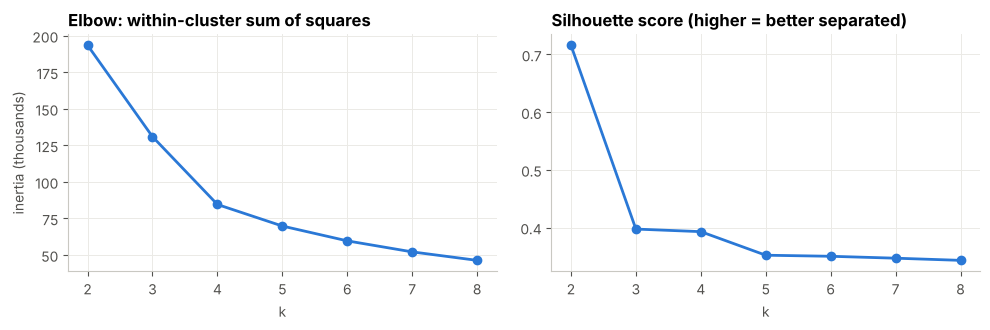

In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(k_scores["k"], k_scores["inertia"] / 1e3, color=BLUE, lw=2, marker="o", ms=6)
a1.set_title("Elbow: within-cluster sum of squares")
a1.set_xlabel("k"); a1.set_ylabel("inertia (thousands)")
a2.plot(k_scores["k"], k_scores["silhouette"], color=BLUE, lw=2, marker="o", ms=6)
a2.set_title("Silhouette score (higher = better separated)")
a2.set_xlabel("k")
fig.tight_layout()
save(fig, "04_kmeans_k_selection")
plt.show()

**Choosing k:** k = 2 has the best silhouette, but it only separates the 3% of repeat buyers from everyone else,
which a simple `frequency > 1` filter already does. The elbow is at **k = 4** (inertia falls 35% from k = 3,
then flattens) and its silhouette (0.39) is close to k = 3, so k = 4 gives more useful segments at almost no
cost in separation.

In [17]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X_rfm)
rfm["cluster"] = kmeans.labels_

profile = (rfm.groupby("cluster")
              .agg(customers=("recency", "size"),
                   recency_median_days=("recency", "median"),
                   avg_orders=("frequency", "mean"),
                   repeat_pct=("frequency", lambda s: 100 * (s > 1).mean()),
                   spend_median=("monetary", "median"),
                   revenue=("monetary", "sum")))
profile["customers_pct"] = 100 * profile["customers"] / profile["customers"].sum()
profile["revenue_pct"] = 100 * profile["revenue"] / profile["revenue"].sum()

# Name clusters from their profile with fixed rules, so the names stay correct if cluster ids change:
#   most orders per customer -> repeat; most recent of the rest -> recent; then split the lapsed by spend
names = {}
names[profile["avg_orders"].idxmax()] = "Repeat customers"
rest = profile.drop(index=list(names))
names[rest["recency_median_days"].idxmin()] = "Recent one-time buyers"
rest = rest.drop(index=list(names), errors="ignore")
names[rest["spend_median"].idxmax()] = "Lapsed big spenders"
names[rest["spend_median"].idxmin()] = "Lapsed low spenders"
rfm["segment"] = rfm["cluster"].map(names)
profile = profile.rename(index=names).sort_values("revenue_pct", ascending=False)
results["rfm"] = profile[["customers", "customers_pct", "revenue_pct", "recency_median_days",
                          "spend_median", "repeat_pct"]].round(2).to_dict("index")
profile.drop(columns="revenue")

,customers,recency_median_days,avg_orders,repeat_pct,spend_median,customers_pct,revenue_pct
cluster,,,,,,,
Lapsed big spenders,32131,264.00,1.00,0.00,200.98,33.83,61.02
Lapsed low spenders,42078,279.00,1.00,0.00,65.78,44.30,18.23
Recent one-time buyers,17887,46.00,1.00,0.00,104.30,18.83,15.09
Repeat customers,2887,206.00,2.11,100.00,225.55,3.04,5.66


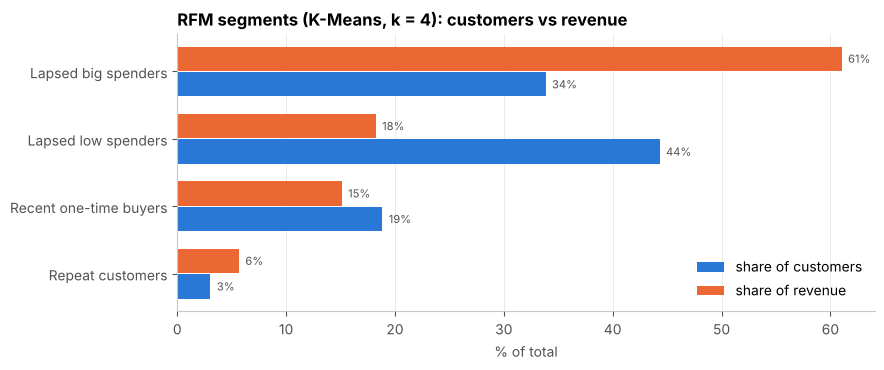

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = np.arange(len(profile))
ax.barh(y + 0.19, profile["customers_pct"], height=0.36, color=BLUE, label="share of customers")
ax.barh(y - 0.19, profile["revenue_pct"], height=0.36, color=ORANGE, label="share of revenue")
for yi, (c, r) in enumerate(zip(profile["customers_pct"], profile["revenue_pct"])):
    ax.text(c + 0.6, yi + 0.19, f"{c:.0f}%", va="center", fontsize=8, color=INK_2)
    ax.text(r + 0.6, yi - 0.19, f"{r:.0f}%", va="center", fontsize=8, color=INK_2)
ax.set_yticks(y, profile.index)
ax.invert_yaxis()
ax.set_xlabel("% of total")
ax.set_title("RFM segments (K-Means, k = 4): customers vs revenue")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
save(fig, "05_rfm_segments")
plt.show()

**What the segments say:** one in three customers ("lapsed big spenders") produced most of the revenue but hasn't
ordered in about nine months, and only 3% of customers ever return. The business is acquisition-driven, so even a
small lift in repeat purchases is valuable. That is the retention experiment sized in Part 4.

## Part 2. Predicting late delivery at purchase time

**Goal:** when an order is placed, score how likely it is to arrive after the date the customer was promised,
so operations can act early (expedite, warn the seller, or message the customer).

**The main risk is leakage.** Many public notebooks on this dataset report 0.9+ AUC because they use columns that
only exist after purchase (carrier hand-off date, approval time, actual delivery date). Every feature here must be
**known at the moment of purchase**, and the history features are computed **point-in-time**: an order may only
see events that finished before it was placed.

### 2.1 Order-level table from SQL
One row per delivered order. For orders with several items, the most expensive item decides the "main" seller and
category (`ROW_NUMBER()` window function).

In [19]:
base = sql("""
WITH items AS (
    SELECT oi.order_id,
           COUNT(*)                                                         AS n_items,
           COUNT(DISTINCT oi.seller_id)                                     AS n_sellers,
           SUM(oi.price)                                                    AS price,
           SUM(oi.freight_value)                                            AS freight,
           SUM(p.product_weight_g)                                          AS weight_g,
           SUM(p.product_length_cm * p.product_height_cm * p.product_width_cm) AS volume_cm3
    FROM order_items oi
    LEFT JOIN products p ON p.product_id = oi.product_id
    GROUP BY oi.order_id
),
main_item AS (                       -- most expensive item -> main seller and category
    SELECT order_id, seller_id, product_category_name
    FROM (SELECT oi.order_id, oi.seller_id, p.product_category_name,
                 ROW_NUMBER() OVER (PARTITION BY oi.order_id
                                    ORDER BY oi.price DESC, oi.order_item_id) AS rn
          FROM order_items oi
          LEFT JOIN products p ON p.product_id = oi.product_id)
    WHERE rn = 1
),
pay AS (
    SELECT order_id,
           MAX(payment_installments)                                        AS installments,
           COALESCE(MAX(CASE WHEN payment_sequential = 1 THEN payment_type END),
                    MAX(payment_type))                                      AS payment_type
    FROM payments
    GROUP BY order_id
)
SELECT d.order_id,
       d.order_purchase_timestamp       AS purchase_ts,
       d.order_estimated_delivery_date  AS estimated_ts,
       d.order_delivered_customer_date  AS delivered_ts,     -- outcome only, never a feature
       o.order_delivered_carrier_date   AS carrier_ts,       -- used ONLY to build seller history
       d.is_late, d.delivery_days, d.promised_days,
       d.customer_state, c.customer_zip_code_prefix AS customer_zip,
       m.seller_id, s.seller_state, s.seller_zip_code_prefix AS seller_zip,
       m.product_category_name AS category,
       i.n_items, i.n_sellers, i.price, i.freight, i.weight_g, i.volume_cm3,
       pay.installments, pay.payment_type
FROM v_order_delivery d
JOIN orders o     ON o.order_id = d.order_id
JOIN customers c  ON c.customer_id = d.customer_id
JOIN items i      ON i.order_id = d.order_id
JOIN main_item m  ON m.order_id = d.order_id
JOIN sellers s    ON s.seller_id = m.seller_id
LEFT JOIN pay     ON pay.order_id = d.order_id
""")
for col in ["purchase_ts", "estimated_ts", "delivered_ts", "carrier_ts"]:
    base[col] = pd.to_datetime(base[col])
base = base.sort_values("purchase_ts").reset_index(drop=True)

# Every order any seller received (any status): used for seller workload and experience
seller_orders = sql("""
SELECT DISTINCT oi.seller_id, o.order_id, o.order_purchase_timestamp AS purchase_ts
FROM order_items oi
JOIN orders o ON o.order_id = oi.order_id
""")
seller_orders["purchase_ts"] = pd.to_datetime(seller_orders["purchase_ts"])

# Zip-code centroids for distance (the raw table has ~1M noisy rows, a few outside Brazil)
zip_geo = sql("""
SELECT geolocation_zip_code_prefix AS zip,
       AVG(geolocation_lat)        AS lat,
       AVG(geolocation_lng)        AS lng
FROM geolocation
WHERE geolocation_lat BETWEEN -34 AND 5.5
  AND geolocation_lng BETWEEN -74 AND -34
GROUP BY geolocation_zip_code_prefix
""").set_index("zip")
print(f"{len(base):,} delivered orders, late rate {base['is_late'].mean():.2%}; "
      f"{len(zip_geo):,} zip centroids")

96,470 delivered orders, late rate 6.77%; 19,010 zip centroids


### 2.2 Features, all known at purchase time

**Point-in-time helper.** For each order placed at time *t*, `trailing_sum` adds up events that finished in
`[t - window, t)`, strictly before *t*. Sorting the events once and using `searchsorted` on cumulative sums makes
this O(n log n) instead of a loop over every pair.

In [20]:
def trailing_sum(ev_times, ev_values, q_times, window=None):
    """Sum of ev_values for events with time in [q - window, q), for every query time q.
    window=None means all history before q. Strictly before q, so an order never sees itself."""
    order = np.argsort(ev_times, kind="stable")
    ev_times, ev_values = ev_times[order], ev_values[order]
    csum = np.concatenate([[0.0], np.cumsum(ev_values)])
    hi = np.searchsorted(ev_times, q_times, side="left")
    lo = 0 if window is None else np.searchsorted(ev_times, q_times - window, side="left")
    return csum[hi] - csum[lo]


def point_in_time(events, ev_time, value, queries, q_time, key=None, window_days=None):
    """trailing_sum within groups (same seller / same state). Returns one value per query row."""
    window = None if window_days is None else np.timedelta64(window_days, "D")
    q_times = queries[q_time].to_numpy("datetime64[ns]")
    if key is None:
        return trailing_sum(events[ev_time].to_numpy("datetime64[ns]"),
                            events[value].to_numpy(float), q_times, window)
    out = np.zeros(len(queries))
    groups = dict(tuple(events.groupby(key)))
    for k, idx in pd.Series(np.arange(len(queries))).groupby(queries[key].to_numpy()):
        g = groups.get(k)
        if g is not None:
            out[idx.values] = trailing_sum(g[ev_time].to_numpy("datetime64[ns]"),
                                           g[value].to_numpy(float), q_times[idx.values], window)
    return out


df = base.copy()
PRIOR_END = pd.Timestamp("2017-11-01")   # smoothing priors use only data finished before the first CV fold
TEST_START = pd.Timestamp("2018-05-01")  # final test period starts here (see 2.3)

# --- order basics (on the order itself, known at checkout) ---
# money and size are heavily right-skewed (a few R$1,000+ freights, 100 kg parcels); log1p keeps those
# outliers from dominating the linear model (tree models are unaffected by monotone transforms)
df["log_price"] = np.log1p(df["price"])
df["log_freight"] = np.log1p(df["freight"])
df["log_freight_ratio"] = np.log1p(df["freight"] / df["price"])
df["log_weight_kg"] = np.log1p(df["weight_g"] / 1000)
df["log_volume_l"] = np.log1p(df["volume_cm3"] / 1000)
df["same_state"] = (df["customer_state"] == df["seller_state"]).astype(int)
df["purchase_hour"] = df["purchase_ts"].dt.hour
df["purchase_dow"] = df["purchase_ts"].dt.dayofweek
df["category"] = df["category"].fillna("unknown")
df["payment_type"] = df["payment_type"].fillna("unknown")

# --- distance seller -> customer (haversine, km) ---
c_ll = zip_geo.reindex(df["customer_zip"]).to_numpy()
s_ll = zip_geo.reindex(df["seller_zip"]).to_numpy()
lat1, lng1, lat2, lng2 = map(np.radians, [c_ll[:, 0], c_ll[:, 1], s_ll[:, 0], s_ll[:, 1]])
h = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lng2 - lng1) / 2) ** 2
df["distance_km"] = 2 * 6371 * np.arcsin(np.sqrt(h))

# --- seller history (only events that finished before this purchase) ---
deliveries = df[["seller_id", "customer_state", "delivered_ts", "is_late", "delivery_days"]].assign(one=1.0)
handoffs = df.dropna(subset=["carrier_ts"])[["seller_id", "carrier_ts", "purchase_ts"]].copy()
handoffs["handling_days"] = ((handoffs["carrier_ts"] - handoffs["purchase_ts"]).dt.total_seconds() / 86400).clip(0, 30)
handoffs["one"] = 1.0
seller_orders["one"] = 1.0

prior_late = df.loc[df["delivered_ts"] < PRIOR_END, "is_late"].mean()
prior_handling = handoffs.loc[handoffs["carrier_ts"] < PRIOR_END, "handling_days"].median()

n_deliv = point_in_time(deliveries, "delivered_ts", "one", df, "purchase_ts", key="seller_id")
n_late = point_in_time(deliveries, "delivered_ts", "is_late", df, "purchase_ts", key="seller_id")
df["seller_late_rate"] = (n_late + 20 * prior_late) / (n_deliv + 20)       # smoothed toward the prior
n_hand = point_in_time(handoffs, "carrier_ts", "one", df, "purchase_ts", key="seller_id")
sum_hand = point_in_time(handoffs, "carrier_ts", "handling_days", df, "purchase_ts", key="seller_id")
df["seller_handling_days"] = (sum_hand + 5 * prior_handling) / (n_hand + 5)
df["seller_experience"] = np.log1p(point_in_time(seller_orders, "purchase_ts", "one", df, "purchase_ts", key="seller_id"))
df["log_seller_load_7d"] = np.log1p(point_in_time(seller_orders, "purchase_ts", "one", df, "purchase_ts",
                                                   key="seller_id", window_days=7))

# --- current conditions: deliveries finished in the last 30 days to this state / 14 days platform-wide ---
n30 = point_in_time(deliveries, "delivered_ts", "one", df, "purchase_ts", key="customer_state", window_days=30)
days30 = point_in_time(deliveries, "delivered_ts", "delivery_days", df, "purchase_ts", key="customer_state", window_days=30)
late30 = point_in_time(deliveries, "delivered_ts", "is_late", df, "purchase_ts", key="customer_state", window_days=30)
with np.errstate(invalid="ignore", divide="ignore"):
    df["state_recent_days"] = np.where(n30 > 0, days30 / n30, np.nan)
    df["state_recent_late"] = np.where(n30 > 0, late30 / n30, np.nan)
    n14 = point_in_time(deliveries, "delivered_ts", "one", df, "purchase_ts", window_days=14)
    late14 = point_in_time(deliveries, "delivered_ts", "is_late", df, "purchase_ts", window_days=14)
    df["platform_recent_late"] = np.where(n14 > 0, late14 / n14, np.nan)

# --- the key engineered feature: how much buffer the promise has over what this route is taking right now ---
df["slack_days"] = df["promised_days"] - df["state_recent_days"]

NUM = ["promised_days", "slack_days", "distance_km", "same_state", "log_price", "log_freight", "log_freight_ratio",
       "log_weight_kg", "log_volume_l", "n_items", "n_sellers", "installments", "seller_late_rate",
       "seller_handling_days", "seller_experience", "log_seller_load_7d", "state_recent_late",
       "platform_recent_late", "purchase_hour", "purchase_dow"]
# state_recent_days is NOT a model input: slack_days = promised_days - state_recent_days exactly, so keeping
# all three would make the logistic-regression coefficients unstable (perfect multicollinearity).
CAT = ["customer_state", "seller_state", "category", "payment_type"]
FEATURES = NUM + CAT
print(f"{len(NUM)} numeric + {len(CAT)} categorical features")
df[NUM].describe().T[["count", "mean", "50%", "min", "max"]]

20 numeric + 4 categorical features


,count,mean,50%,min,max
promised_days,"96,470.00",23.74,23.23,2.01,155.14
slack_days,"96,071.00",11.03,10.52,-122.68,138.96
distance_km,"95,993.00",600.37,433.81,0.00,"3,399.19"
same_state,"96,470.00",0.36,0.00,0.00,1.00
log_price,"96,470.00",4.46,4.47,0.62,9.51
log_freight,"96,470.00",2.99,2.90,0.00,7.49
log_freight_ratio,"96,470.00",0.25,0.20,0.00,3.11
log_weight_kg,"96,454.00",0.83,0.56,0.00,5.22
log_volume_l,"96,454.00",2.24,2.11,0.16,7.30
n_items,"96,470.00",1.14,1.00,1.00,21.00


In [21]:
# Leakage audit: what each feature is and why it is available at checkout
audit = pd.DataFrame([
    ("promised_days", "estimated date shown at checkout - purchase time", "yes, shown to the customer"),
    ("slack_days", "promised_days - avg delivery days to this state in the last 30 days", "yes, from finished deliveries only"),
    ("distance_km", "haversine distance between seller and customer zip centroids", "yes, both addresses known"),
    ("log price, freight, weight, volume; items", "basket contents (log1p for the skewed ones)", "yes, in the cart"),
    ("installments, payment_type", "payment choice", "yes, chosen at checkout"),
    ("seller_late_rate", "seller's late share over deliveries finished before purchase (smoothed)", "yes, point-in-time"),
    ("seller_handling_days", "seller's avg purchase-to-carrier time over earlier hand-offs", "yes, point-in-time"),
    ("log_seller_load_7d, seller_experience", "log orders the seller received in the last 7 days / ever", "yes, point-in-time"),
    ("state_recent_late, platform_recent_late", "late share of deliveries finished in the last 30 / 14 days", "yes, point-in-time"),
    ("EXCLUDED: approved_at, carrier date, delivered date, reviews", "happen after purchase", "no, would leak the answer"),
    ("EXCLUDED: purchase month, platform order volume", "proxies for the time period", "kept out on purpose, see 2.6"),
], columns=["feature", "definition", "known at purchase?"])
audit

,feature,definition,known at purchase?
0,promised_days,estimated date shown at checkout - purchase time,"yes, shown to the customer"
1,slack_days,promised_days - avg delivery days to this stat...,"yes, from finished deliveries only"
2,distance_km,haversine distance between seller and customer...,"yes, both addresses known"
3,"log price, freight, weight, volume; items",basket contents (log1p for the skewed ones),"yes, in the cart"
4,"installments, payment_type",payment choice,"yes, chosen at checkout"
5,seller_late_rate,seller's late share over deliveries finished b...,"yes, point-in-time"
6,seller_handling_days,seller's avg purchase-to-carrier time over ear...,"yes, point-in-time"
7,"log_seller_load_7d, seller_experience",log orders the seller received in the last 7 d...,"yes, point-in-time"
8,"state_recent_late, platform_recent_late",late share of deliveries finished in the last ...,"yes, point-in-time"
9,"EXCLUDED: approved_at, carrier date, delivered...",happen after purchase,"no, would leak the answer"


### 2.3 Validation design: train on the past, test on the future
A random split would let the model train on orders placed **after** the ones it is tested on. Delivery conditions
change a lot over time (the monthly late rate swings between 1% and 19%), so every evaluation here trains on the
past and scores the future. Two rules:

1. **Test set:** orders placed May–Aug 2018. Untouched until the very end.
2. **Labels must have been knowable.** On the day a model is trained, an order's late/on-time label only exists if
   it has already been delivered. So each training set contains only orders **delivered** before the cut-off.
   Otherwise orders placed just before the cut-off and delivered during the scored period would leak that
   period's delivery conditions into training.

**Model selection uses rolling-origin time-series cross-validation**: 6 monthly folds from Nov 2017 to Apr 2018.
For each fold month, the model trains on every order delivered before that month starts and is scored on orders
placed in that month. Averaging 6 folds is more reliable than a single validation window, because one window can
land on an unusual month.

In [22]:
df = df[df["purchase_ts"] >= "2017-01-01"].reset_index(drop=True)   # 2016 is too thin to learn from
CV_FOLDS = pd.date_range("2017-11-01", "2018-04-01", freq="MS")       # 6 monthly folds
df["split"] = np.where(df["purchase_ts"] >= TEST_START, "test", "development")

X = df[FEATURES]
y = df["is_late"].to_numpy()
te = (df["split"] == "test").to_numpy()
fit_final = ((df["split"] == "development") & (df["delivered_ts"] < TEST_START)).to_numpy()

fold_info = pd.DataFrame([{
    "fold": f"{start:%b %Y}",
    "train orders (delivered before)": int((df["delivered_ts"] < start).sum()),
    "scored orders": int(((df["purchase_ts"] >= start) & (df["purchase_ts"] < start + pd.offsets.MonthBegin(1))).sum()),
    "late rate %": 100 * df.loc[(df["purchase_ts"] >= start) & (df["purchase_ts"] < start + pd.offsets.MonthBegin(1)), "is_late"].mean(),
} for start in CV_FOLDS])
fold_info.loc[len(fold_info)] = ["TEST May-Aug 2018", int(fit_final.sum()), int(te.sum()), 100 * y[te].mean()]
fold_info

,fold,train orders (delivered before),scored orders,late rate %
0,Nov 2017,29055,7288,12.40
1,Dec 2017,33725,5513,7.46
2,Jan 2018,40930,7069,5.70
3,Feb 2018,47527,6555,14.13
4,Mar 2018,53377,7003,18.96
5,Apr 2018,60201,6798,4.50
6,TEST May-Aug 2018,68051,25352,4.40


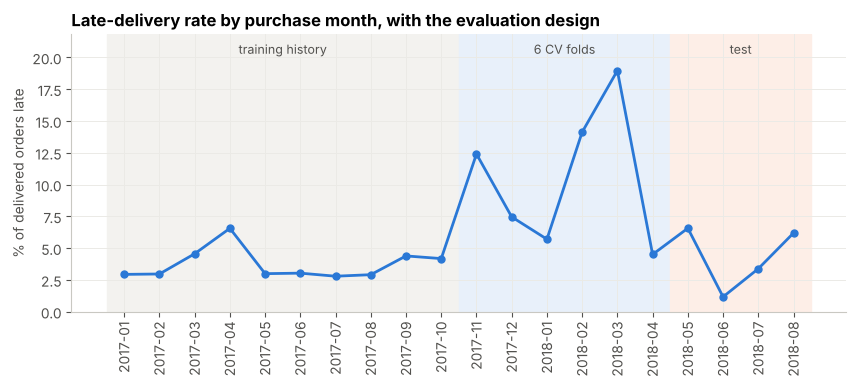

In [23]:
late_by_month = df.groupby(df["purchase_ts"].dt.to_period("M"))["is_late"].mean() * 100
labels = list(late_by_month.index.astype(str))
fig, ax = plt.subplots(figsize=(10, 3.6))
for name, lo, hi, shade in [("training history", "2017-01", "2017-10", "#f3f2ef"),
                            ("6 CV folds", "2017-11", "2018-04", "#e8f0fa"),
                            ("test", "2018-05", "2018-08", "#fdeee7")]:
    i0, i1 = labels.index(lo), labels.index(hi)
    ax.axvspan(i0 - 0.5, i1 + 0.5, color=shade, zorder=0)
    ax.text((i0 + i1) / 2, late_by_month.max() * 1.07, name, ha="center", color=INK_2, fontsize=9)
ax.plot(range(len(labels)), late_by_month.values, color=BLUE, lw=2, marker="o", ms=5)
ax.set_xticks(range(len(labels)), labels, rotation=90)
ax.set_ylim(0, late_by_month.max() * 1.15)
ax.set_ylabel("% of delivered orders late")
ax.set_title("Late-delivery rate by purchase month, with the evaluation design")
save(fig, "06_late_rate_split")
plt.show()

### 2.4 Three models compared with rolling cross-validation
- **Logistic Regression**: linear baseline; numeric features standardised, categoricals one-hot encoded.
- **Random Forest**: bagged trees, captures interactions.
- **Gradient Boosting**: scikit-learn's `HistGradientBoostingClassifier` (the same histogram algorithm as LightGBM).

Only ~7% of orders are late, so every model uses `class_weight="balanced"`. Categories with < 50 orders are pooled
into one "infrequent" bucket so one-hot encoding doesn't overfit tiny states or categories.

**Metrics.** ROC-AUC and PR-AUC (average precision) measure how well the model ranks orders, without a threshold.
PR-AUC matters more for a rare positive class, so it is the selection metric. For a business operating point I
**flag the riskiest 10% of orders** (a volume an operations team can act on) and report precision, recall and F1 at
that cut-off. A fixed probability threshold would break when the late rate shifts between periods; a top-10% rule
doesn't. (The class weights also make raw probabilities too high, so they are used for ranking, not as
calibrated probabilities.)

*Runtime: about 5 minutes on 2 CPU cores (54 model fits).*

In [24]:
def make_pipeline(kind: str, **params) -> Pipeline:
    onehot = dict(handle_unknown="ignore", min_frequency=50)
    if kind == "lr":
        prep = ColumnTransformer([
            ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM),
            ("cat", OneHotEncoder(**onehot), CAT)])
        model = LogisticRegression(class_weight="balanced", max_iter=5000, **params)
    elif kind == "rf":
        prep = ColumnTransformer([
            ("num", SimpleImputer(strategy="median"), NUM),
            ("cat", OneHotEncoder(sparse_output=False, **onehot), CAT)])
        model = RandomForestClassifier(n_estimators=200, max_features="sqrt", class_weight="balanced_subsample",
                                       n_jobs=-1, random_state=RANDOM_STATE, **params)
    else:  # gradient boosting handles missing values natively, so no imputer
        prep = ColumnTransformer([
            ("num", "passthrough", NUM),
            ("cat", OneHotEncoder(sparse_output=False, **onehot), CAT)])
        model = HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, l2_regularization=1.0,
                                               early_stopping=False, random_state=RANDOM_STATE, **params)
    return Pipeline([("prep", prep), ("model", model)])


def scores(y_true, p, flag_rate=0.10) -> dict:
    """Ranking metrics, plus precision/recall/F1 when flagging the riskiest `flag_rate` of orders."""
    flagged = (p >= np.quantile(p, 1 - flag_rate)).astype(int)
    prec = precision_score(y_true, flagged)
    return {"ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "precision@10%": prec, "recall@10%": recall_score(y_true, flagged),
            "F1@10%": f1_score(y_true, flagged), "lift@10%": prec / np.mean(y_true)}


def rolling_cv(kind: str, params: dict) -> pd.DataFrame:
    """Score one model configuration on each monthly fold, training only on labels known before the fold."""
    rows = []
    for start in CV_FOLDS:
        end = start + pd.offsets.MonthBegin(1)
        fit_mask = (df["delivered_ts"] < start).to_numpy()
        eval_mask = ((df["purchase_ts"] >= start) & (df["purchase_ts"] < end)).to_numpy()
        pipe = make_pipeline(kind, **params).fit(X[fit_mask], y[fit_mask])
        rows.append({"fold": f"{start:%Y-%m}", **scores(y[eval_mask], pipe.predict_proba(X[eval_mask])[:, 1])})
    return pd.DataFrame(rows)


GRID = {
    "Logistic Regression": ("lr", [{"C": 0.05}, {"C": 0.5}, {"C": 5.0}]),
    "Random Forest": ("rf", [{"min_samples_leaf": 10}, {"min_samples_leaf": 50}, {"min_samples_leaf": 150}]),
    "Gradient Boosting": ("hgb", [{"learning_rate": 0.03, "max_leaf_nodes": 15, "min_samples_leaf": 200},
                                  {"learning_rate": 0.05, "max_leaf_nodes": 31, "min_samples_leaf": 100},
                                  {"learning_rate": 0.10, "max_leaf_nodes": 15, "min_samples_leaf": 200}]),
}
cv_rows, cv_folds = [], {}
for name, (kind, grid) in GRID.items():
    for params in grid:
        folds = rolling_cv(kind, params)
        cv_folds[(name, json.dumps(params))] = folds
        cv_rows.append({"model": name, "params": json.dumps(params),
                        "PR-AUC mean": folds["PR-AUC"].mean(), "PR-AUC std": folds["PR-AUC"].std(),
                        "ROC-AUC mean": folds["ROC-AUC"].mean(), "ROC-AUC std": folds["ROC-AUC"].std(),
                        "recall@10% mean": folds["recall@10%"].mean(), "F1@10% mean": folds["F1@10%"].mean()})
cv_results = pd.DataFrame(cv_rows)
cv_results.round(3)

,model,params,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std,recall@10% mean,F1@10% mean
0,Logistic Regression,"{""C"": 0.05}",0.20,0.10,0.69,0.07,0.25,0.23
1,Logistic Regression,"{""C"": 0.5}",0.20,0.10,0.68,0.07,0.24,0.23
2,Logistic Regression,"{""C"": 5.0}",0.20,0.10,0.68,0.07,0.24,0.22
3,Random Forest,"{""min_samples_leaf"": 10}",0.18,0.11,0.67,0.06,0.22,0.21
4,Random Forest,"{""min_samples_leaf"": 50}",0.19,0.12,0.68,0.06,0.23,0.21
5,Random Forest,"{""min_samples_leaf"": 150}",0.19,0.12,0.68,0.05,0.23,0.22
6,Gradient Boosting,"{""learning_rate"": 0.03, ""max_leaf_nodes"": 15, ...",0.18,0.10,0.66,0.06,0.22,0.21
7,Gradient Boosting,"{""learning_rate"": 0.05, ""max_leaf_nodes"": 31, ...",0.17,0.09,0.64,0.07,0.19,0.18
8,Gradient Boosting,"{""learning_rate"": 0.1, ""max_leaf_nodes"": 15, ""...",0.17,0.09,0.64,0.05,0.20,0.19


In [25]:
# Best configuration per model family (highest mean PR-AUC across folds), and the overall winner
best_cfg = cv_results.loc[cv_results.groupby("model")["PR-AUC mean"].idxmax()].set_index("model")
best_name = best_cfg["PR-AUC mean"].idxmax()
best_params = best_cfg["params"].map(json.loads)
fold_auc = pd.DataFrame({name: cv_folds[(name, best_cfg.loc[name, "params"])].set_index("fold")["ROC-AUC"]
                         for name in GRID})
print(f"Selected by rolling CV (mean PR-AUC): {best_name} {best_cfg.loc[best_name, 'params']}")
print("\nROC-AUC of each family's best configuration, fold by fold:")
display(fold_auc.round(3))
results["cv"] = {"selected": best_name,
                 "best_per_family": best_cfg[["params", "PR-AUC mean", "ROC-AUC mean", "ROC-AUC std"]].round(4).to_dict("index")}
best_cfg[["params", "PR-AUC mean", "PR-AUC std", "ROC-AUC mean", "ROC-AUC std"]].round(3)

Selected by rolling CV (mean PR-AUC): Logistic Regression {"C": 0.05}

ROC-AUC of each family's best configuration, fold by fold:


,Logistic Regression,Random Forest,Gradient Boosting
fold,,,
2017-11,0.63,0.61,0.58
2017-12,0.64,0.64,0.62
2018-01,0.62,0.67,0.66
2018-02,0.72,0.70,0.67
2018-03,0.70,0.71,0.68
2018-04,0.80,0.76,0.76


,params,PR-AUC mean,PR-AUC std,ROC-AUC mean,ROC-AUC std
model,,,,,
Gradient Boosting,"{""learning_rate"": 0.03, ""max_leaf_nodes"": 15, ...",0.18,0.10,0.66,0.06
Logistic Regression,"{""C"": 0.05}",0.20,0.10,0.69,0.07
Random Forest,"{""min_samples_leaf"": 150}",0.19,0.12,0.68,0.05


### 2.5 Final test: refit on everything known by 1 May 2018, score May–Aug 2018 once

In [26]:
final_models, test_probs, test_rows = {}, {}, []
for name, (kind, _) in GRID.items():
    pipe = make_pipeline(kind, **best_params[name]).fit(X[fit_final], y[fit_final])
    final_models[name] = pipe
    test_probs[name] = pipe.predict_proba(X[te])[:, 1]
    test_rows.append({"model": name, **scores(y[te], test_probs[name])})
test_results = pd.DataFrame(test_rows).set_index("model")
print(f"Trained on {fit_final.sum():,} orders; tested on {te.sum():,} orders (late rate {y[te].mean():.2%}).")
results["model"] = {"train_orders": int(fit_final.sum()), "test_orders": int(te.sum()),
                    "test_late_rate": float(y[te].mean()), "selected_model": best_name,
                    "test": test_results.round(4).to_dict("index")}
test_results.round(3)

Trained on 68,051 orders; tested on 25,352 orders (late rate 4.40%).


,ROC-AUC,PR-AUC,precision@10%,recall@10%,F1@10%,lift@10%
model,,,,,,
Logistic Regression,0.72,0.10,0.11,0.25,0.15,2.51
Random Forest,0.62,0.08,0.10,0.23,0.14,2.26
Gradient Boosting,0.71,0.10,0.11,0.25,0.15,2.54


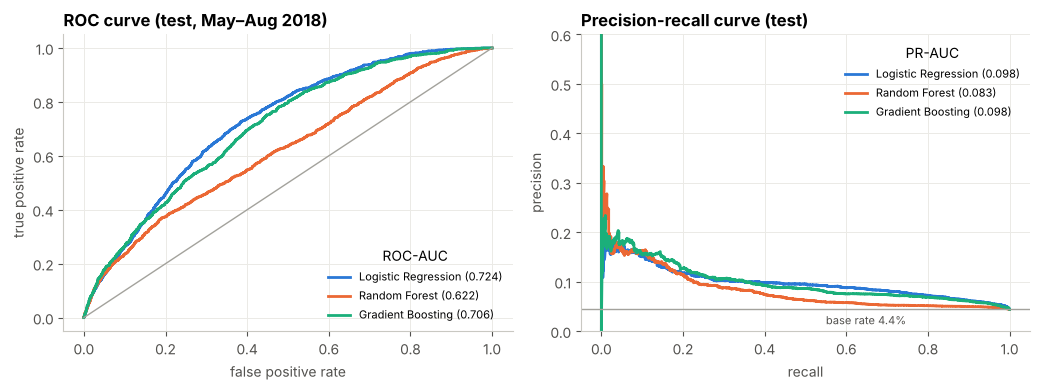

In [27]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 4))
colors = {"Logistic Regression": BLUE, "Random Forest": ORANGE, "Gradient Boosting": AQUA}
for name, p in test_probs.items():
    fpr, tpr, _ = roc_curve(y[te], p)
    a1.plot(fpr, tpr, color=colors[name], lw=2, label=f"{name} ({roc_auc_score(y[te], p):.3f})")
    prec, rec, _ = precision_recall_curve(y[te], p)
    a2.plot(rec, prec, color=colors[name], lw=2, label=f"{name} ({average_precision_score(y[te], p):.3f})")
a1.plot([0, 1], [0, 1], color=GRAY, lw=1)
a1.set(title="ROC curve (test, May–Aug 2018)", xlabel="false positive rate", ylabel="true positive rate")
a2.axhline(y[te].mean(), color=GRAY, lw=1)
a2.text(0.55, y[te].mean() - 0.03, f"base rate {y[te].mean():.1%}", color=INK_2, fontsize=8)
a2.set(title="Precision-recall curve (test)", xlabel="recall", ylabel="precision", ylim=(0, 0.6))
a1.legend(loc="lower right", title="ROC-AUC", fontsize=8)
a2.legend(loc="upper right", title="PR-AUC", fontsize=8)
fig.tight_layout()
save(fig, "07_roc_pr_curves")
plt.show()

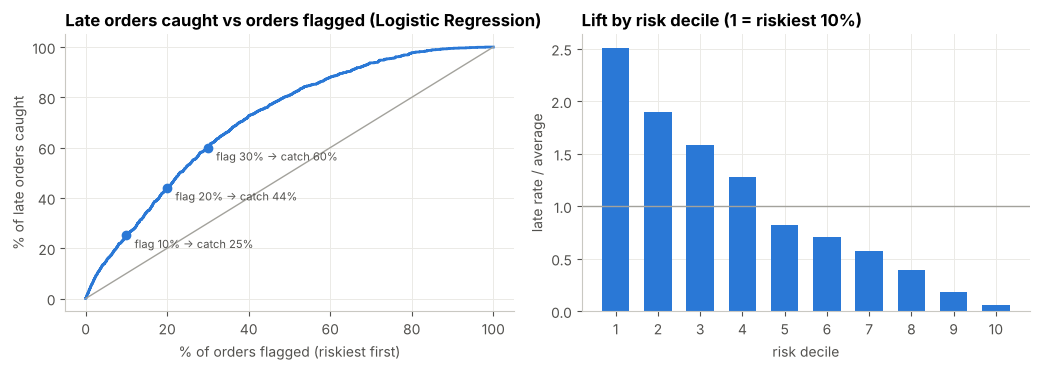

,size,mean,lift
decile,,,
1,2536,0.11,2.51
2,2535,0.08,1.89
3,2535,0.07,1.59
4,2535,0.06,1.27
5,2535,0.04,0.82
6,2535,0.03,0.71
7,2535,0.03,0.57
8,2535,0.02,0.40
9,2535,0.01,0.18


In [28]:
# Business view of the selected model: share of late orders caught for each share of orders flagged
p_best = test_probs[best_name]
order = np.argsort(-p_best)
caught = np.cumsum(y[te][order]) / y[te].sum()
share = np.arange(1, len(order) + 1) / len(order)
decile = pd.qcut(pd.Series(p_best).rank(method="first", ascending=False), 10, labels=range(1, 11))
lift_table = pd.DataFrame({"decile": decile, "late": y[te]}).groupby("decile", observed=True)["late"].agg(["size", "mean"])
lift_table["lift"] = lift_table["mean"] / y[te].mean()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.8))
a1.plot(share * 100, caught * 100, color=BLUE, lw=2)
a1.plot([0, 100], [0, 100], color=GRAY, lw=1)
for f in (0.1, 0.2, 0.3):
    c = caught[int(f * len(order)) - 1] * 100
    a1.plot(f * 100, c, "o", color=BLUE, ms=6)
    a1.text(f * 100 + 2, c - 5, f"flag {f:.0%} -> catch {c:.0f}%", fontsize=8, color=INK_2)
a1.set(title=f"Late orders caught vs orders flagged ({best_name})",
       xlabel="% of orders flagged (riskiest first)", ylabel="% of late orders caught")
a2.bar(lift_table.index.astype(int), lift_table["lift"], color=BLUE, width=0.65)
a2.axhline(1, color=GRAY, lw=1)
a2.set(title="Lift by risk decile (1 = riskiest 10%)", xlabel="risk decile", ylabel="late rate / average")
a2.set_xticks(range(1, 11))
fig.tight_layout()
save(fig, "08_capture_and_lift")
plt.show()
results["model"]["capture_at"] = {f"{int(f * 100)}%": float(caught[int(f * len(order)) - 1]) for f in (0.1, 0.2, 0.3)}
results["model"]["top_decile_late_rate"] = float(lift_table["mean"].iloc[0])
results["model"]["bottom_half_late_rate"] = float(y[te][order[len(order) // 2:]].mean())
lift_table.round(3)

### 2.6 Why the time-based design matters: the same models on a random split
Same features and settings, but a random 75/25 split that mixes all periods. The gap shows how much a careless
evaluation would overstate real-world performance. Tree models gain the most, because with a random split they can
memorise period-specific delivery conditions from orders placed around the same time as the test orders. The same
reason is why purchase month and platform-wide order volume are not features: in early experiments the tree models
leaned on them heavily, and they don't carry over to a new period.

In [29]:
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
leak_rows = []
for name, (kind, _) in GRID.items():
    pipe = make_pipeline(kind, **best_params[name]).fit(X_tr_r, y_tr_r)
    leak_rows.append({"model": name,
                      "ROC-AUC random split": roc_auc_score(y_te_r, pipe.predict_proba(X_te_r)[:, 1]),
                      "ROC-AUC time split (test)": test_results.loc[name, "ROC-AUC"]})
leak = pd.DataFrame(leak_rows).set_index("model")
leak["overstated by"] = leak["ROC-AUC random split"] - leak["ROC-AUC time split (test)"]
results["model"]["random_vs_time_split"] = leak.round(4).to_dict("index")
leak.round(3)

,ROC-AUC random split,ROC-AUC time split (test),overstated by
model,,,
Logistic Regression,0.75,0.72,0.03
Random Forest,0.77,0.62,0.15
Gradient Boosting,0.80,0.71,0.09


## Part 3. Explaining the model

Four complementary views:
1. **Permutation importance** (model-agnostic): how much test PR-AUC drops when one feature is shuffled.
   Categorical features are shuffled as a whole, so "customer_state" is one feature, not 27 dummies.
2. **Logistic regression coefficients**: direction and size of each effect, as odds ratios.
3. **SHAP values for the logistic regression**, computed exactly (for a linear model, a feature's SHAP value is
   its coefficient × how far the order's value is from the average), giving per-order "reason codes".
4. **Partial dependence** for the gradient-boosting model, to see non-linear shapes.

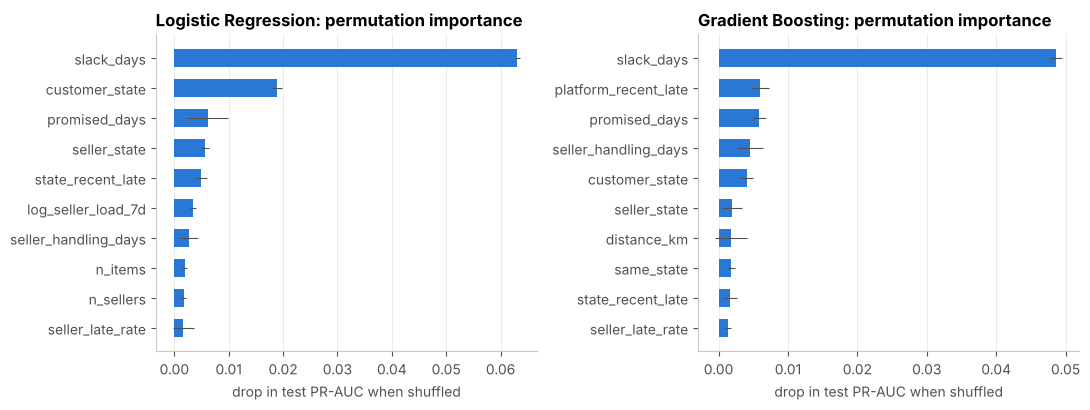

,feature,PR-AUC drop,std
0,slack_days,0.06,0.00
1,customer_state,0.02,0.00
2,promised_days,0.01,0.00
3,seller_state,0.01,0.00
4,state_recent_late,0.00,0.00
5,log_seller_load_7d,0.00,0.00
6,seller_handling_days,0.00,0.00
7,n_items,0.00,0.00
8,n_sellers,0.00,0.00
9,seller_late_rate,0.00,0.00


In [30]:
X_test, y_test = X[te], y[te]
other_name = "Gradient Boosting" if best_name != "Gradient Boosting" else "Logistic Regression"


def perm_importance(name: str) -> pd.DataFrame:
    r = permutation_importance(final_models[name], X_test, y_test, scoring="average_precision",
                               n_repeats=5, random_state=RANDOM_STATE)
    return (pd.DataFrame({"feature": FEATURES, "PR-AUC drop": r.importances_mean, "std": r.importances_std})
              .sort_values("PR-AUC drop", ascending=False).reset_index(drop=True))


pi_best, pi_other = perm_importance(best_name), perm_importance(other_name)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, pi) in zip(axes, [(best_name, pi_best), (other_name, pi_other)]):
    d = pi.head(10).iloc[::-1]
    ax.barh(d["feature"], d["PR-AUC drop"], xerr=d["std"], color=BLUE, height=0.6,
            error_kw={"ecolor": INK_2, "lw": 0.8})
    ax.set_title(f"{name}: permutation importance")
    ax.set_xlabel("drop in test PR-AUC when shuffled")
    ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "09_permutation_importance")
plt.show()
results["explain"] = {"perm_importance_" + best_name: pi_best.head(8).round(4).to_dict("records"),
                      "perm_importance_" + other_name: pi_other.head(8).round(4).to_dict("records")}
pi_best.head(10).round(4)

### 3.2 Logistic regression coefficients
Numeric features are standardised, so each coefficient is the change in log-odds for a **+1 standard deviation**
change, and `exp(coef)` is the odds ratio. Positive (red) raises the risk of a late delivery.

**Read `slack_days` and `promised_days` together.** Slack = promised days − how long deliveries to that state are
currently taking. So the slack coefficient is the effect of more buffer, and the promised-days coefficient
(holding slack fixed) is really the effect of a route that is currently slow.

**Don't over-read single signs.** Coefficients are *conditional* on every other feature. Two examples that look odd
on their own: the recent late-rate features come out slightly negative, because periods after a disruption also
get longer promises (more slack), which the slack feature already captures; and São Paulo's dummy raises risk even
though SP has the lowest late rate, because SP gets very tight promises, so at the *same* promise and slack it is
riskier. One-hot categories have no dropped baseline here (the L2 penalty keeps them identifiable), so state terms
compare states with each other. Permutation importance (3.1) is the better guide to what matters overall.

Categorical terms that raise risk most:


,term,coef,odds_ratio
37,cat__customer_state_RJ,1.26,3.53
43,cat__customer_state_SP,1.13,3.10
41,cat__customer_state_SC,0.58,1.79
51,cat__seller_state_MA,0.55,1.74
26,cat__customer_state_ES,0.51,1.67


Categorical terms that lower risk most:


,term,coef,odds_ratio
22,cat__customer_state_AM,-1.27,0.28
39,cat__customer_state_RO,-0.90,0.41
32,cat__customer_state_PA,-0.83,0.44
102,cat__category_moveis_escritorio,-0.59,0.56
20,cat__customer_state_AC,-0.54,0.58


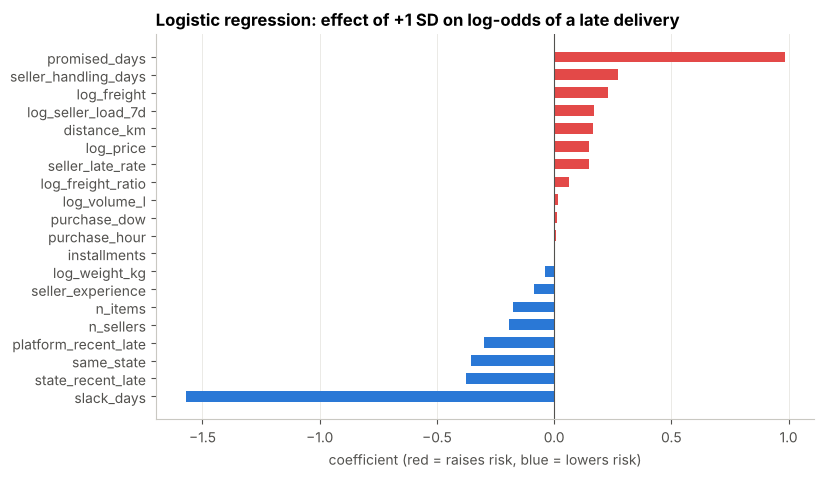

,feature,coef,odds_ratio,one_sd
1,slack_days,-1.57,0.21,7.10
0,promised_days,0.98,2.67,7.76
16,state_recent_late,-0.38,0.69,0.06
3,same_state,-0.35,0.70,0.48
17,platform_recent_late,-0.30,0.74,0.05
13,seller_handling_days,0.27,1.31,1.40
5,log_freight,0.23,1.26,0.51
10,n_sellers,-0.19,0.82,0.12
9,n_items,-0.17,0.84,0.54
15,log_seller_load_7d,0.17,1.19,1.15


In [31]:
lr_pipe = final_models["Logistic Regression"]
prep, lr = lr_pipe.named_steps["prep"], lr_pipe.named_steps["model"]
terms = prep.get_feature_names_out()
coefs = pd.DataFrame({"term": terms, "coef": lr.coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coef"])

sd = pd.Series(prep.named_transformers_["num"].named_steps["scale"].scale_, index=NUM)
num_coefs = (coefs[coefs["term"].str.startswith("num__")]
             .assign(feature=lambda d: d["term"].str[5:])
             .assign(one_sd=lambda d: d["feature"].map(sd)))

fig, ax = plt.subplots(figsize=(8.5, 5))
d = num_coefs.sort_values("coef")
ax.barh(d["feature"], d["coef"], color=np.where(d["coef"] > 0, RED, BLUE), height=0.6)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Logistic regression: effect of +1 SD on log-odds of a late delivery")
ax.set_xlabel("coefficient (red = raises risk, blue = lowers risk)")
ax.grid(axis="y", visible=False)
save(fig, "10_lr_coefficients")
plt.show()

cat_coefs = coefs[coefs["term"].str.startswith("cat__")].sort_values("coef")
print("Categorical terms that raise risk most:")
display(cat_coefs.tail(5).iloc[::-1].round(3))
print("Categorical terms that lower risk most:")
display(cat_coefs.head(5).round(3))
num_coefs.sort_values("coef", key=abs, ascending=False)[["feature", "coef", "odds_ratio", "one_sd"]].round(3)

In [32]:
# Plain-English reading of the strongest numeric effects
for r in num_coefs.sort_values("coef", key=abs, ascending=False).head(5).itertuples():
    change = f"{(r.odds_ratio - 1):+.0%}"
    print(f"{r.feature:<22} +1 SD (= {r.one_sd:,.2f}) -> odds of a late delivery x{r.odds_ratio:.2f} ({change})")
results["explain"]["lr_top_coefficients"] = (num_coefs.sort_values("coef", key=abs, ascending=False)
                                             .head(6)[["feature", "coef", "odds_ratio", "one_sd"]].round(3).to_dict("records"))

slack_days             +1 SD (= 7.10) -> odds of a late delivery x0.21 (-79%)
promised_days          +1 SD (= 7.76) -> odds of a late delivery x2.67 (+167%)
state_recent_late      +1 SD (= 0.06) -> odds of a late delivery x0.69 (-31%)
same_state             +1 SD (= 0.48) -> odds of a late delivery x0.70 (-30%)
platform_recent_late   +1 SD (= 0.05) -> odds of a late delivery x0.74 (-26%)


### 3.3 SHAP values for the logistic regression: global importance and per-order reason codes
For a linear model with features treated as independent, the SHAP value of a feature for one order is exactly
`coef × (x − mean(x))` in log-odds, where the mean is over the training data. That's what `shap.LinearExplainer`
computes, so no library is needed. The contributions plus the base value add up to the model's log-odds for that
order (checked below). Dummy columns of one categorical feature are summed back into that feature.

Check passed: base value + SHAP contributions = model log-odds for every test order


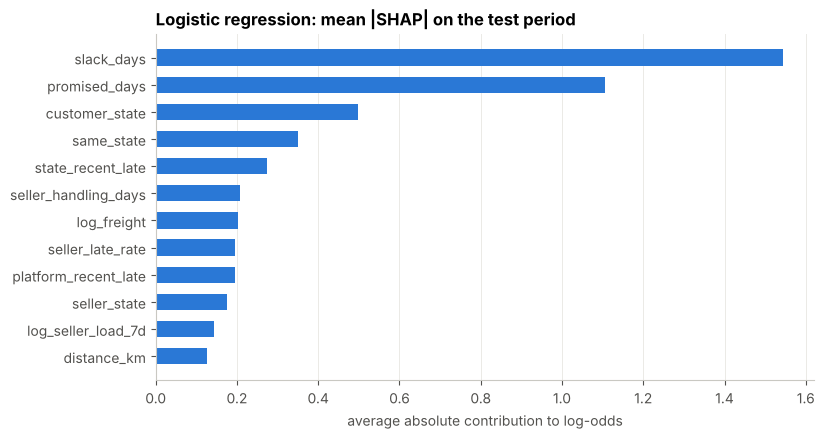

In [33]:
def dense(m):
    return m.toarray() if hasattr(m, "toarray") else np.asarray(m)


mean_t = np.asarray(prep.transform(X[fit_final]).mean(axis=0)).ravel()   # average order in training data
Xt_test = dense(prep.transform(X_test))
shap_terms = (Xt_test - mean_t) * lr.coef_[0]                            # orders x terms, log-odds units
base_value = lr.intercept_[0] + mean_t @ lr.coef_[0]
assert np.allclose(base_value + shap_terms.sum(axis=1), lr_pipe.decision_function(X_test)), "SHAP must add up"

term_feature = [t[5:] if t.startswith("num__") else next(c for c in CAT if t.startswith(f"cat__{c}_"))
                for t in terms]
shap_df = pd.DataFrame(shap_terms, columns=terms).T.groupby(term_feature).sum().T   # orders x features
global_shap = shap_df.abs().mean().sort_values(ascending=False)
print("Check passed: base value + SHAP contributions = model log-odds for every test order")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
d = global_shap.head(12).iloc[::-1]
ax.barh(d.index, d.values, color=BLUE, height=0.6)
ax.set_title("Logistic regression: mean |SHAP| on the test period")
ax.set_xlabel("average absolute contribution to log-odds")
ax.grid(axis="y", visible=False)
save(fig, "11_shap_global")
plt.show()
results["explain"]["shap_global_top"] = global_shap.head(8).round(4).to_dict()

In [34]:
# Reason codes for the riskiest order in the test period: what an ops dashboard would show next to the flag
lr_prob = lr_pipe.predict_proba(X_test)[:, 1]
i = int(np.argmax(lr_prob))
row = X_test.iloc[i]
reasons = (pd.DataFrame({"feature": shap_df.columns, "value": [row[f] for f in shap_df.columns],
                         "contribution (log-odds)": shap_df.iloc[i].values})
             .sort_values("contribution (log-odds)", ascending=False))
order_id = df.loc[te, "order_id"].iloc[i]
outcome = "late" if y_test[i] else "on time"
print(f"Order {order_id[:12]}…  risk rank #1 of {len(X_test):,}  |  actual outcome: {outcome}")
print(f"Base log-odds {base_value:.2f} + contributions {reasons['contribution (log-odds)'].sum():.2f} "
      f"= {base_value + reasons['contribution (log-odds)'].sum():.2f}")
reasons.head(6).round(3)

Order ac4b7ecdaaa6…  risk rank #1 of 25,352  |  actual outcome: on time
Base log-odds -0.38 + contributions 5.86 = 5.48


,feature,value,contribution (log-odds)
22,slack_days,-3.30,3.25
14,promised_days,39.05,1.86
4,log_freight,4.27,0.59
2,distance_km,"2,367.52",0.50
23,state_recent_late,0.00,0.33
20,seller_late_rate,0.08,0.31


### 3.4 Partial dependence (gradient boosting): the shape of the main effects
Average predicted risk as one feature moves and everything else stays as observed. The y-axis is relative (class
weights inflate the probabilities); the slope and shape are what matter.

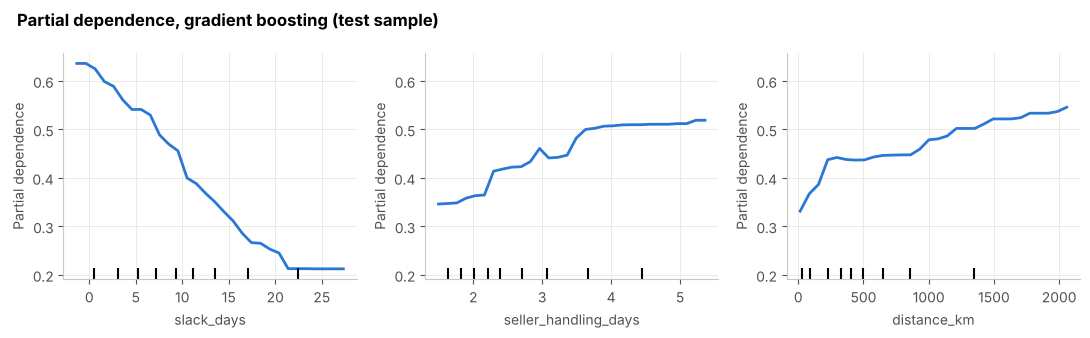

In [35]:
pdp_features = [f for f in ["slack_days", "seller_handling_days", "distance_km"] if f in NUM]
fig, axes = plt.subplots(1, len(pdp_features), figsize=(11, 3.4))
PartialDependenceDisplay.from_estimator(final_models["Gradient Boosting"],
                                        X_test.sample(4000, random_state=RANDOM_STATE),
                                        pdp_features, ax=axes, grid_resolution=30,
                                        line_kw={"color": BLUE, "lw": 2})
fig.suptitle("Partial dependence, gradient boosting (test sample)", x=0.02, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "12_partial_dependence")
plt.show()

### 3.5 Optional: SHAP for the gradient-boosting model with the `shap` library
The `shap` package couldn't be installed in the environment that produced these outputs, so this cell skips
itself here; the permutation importance and exact linear SHAP above are the explanation of record. On a machine
with `pip install shap`, it runs a model-agnostic SHAP explainer on the boosting pipeline and draws a beeswarm.

In [36]:
try:
    import shap
except ImportError:
    shap = None
    print("shap is not installed here, so this cell is skipped. To run it: pip install shap, then re-run.")

if shap is not None:
    gb = final_models["Gradient Boosting"]
    background = X[fit_final].sample(200, random_state=RANDOM_STATE)
    explain_rows = X_test.sample(500, random_state=RANDOM_STATE)
    dtypes = X.dtypes

    def gb_risk(data):
        # shap passes numpy arrays; rebuild the DataFrame with the right dtypes for the pipeline
        return gb.predict_proba(pd.DataFrame(data, columns=FEATURES).astype(dtypes))[:, 1]

    explainer = shap.Explainer(gb_risk, background)       # model-agnostic (permutation) explainer
    shap_values = explainer(explain_rows)
    shap.plots.beeswarm(shap_values, max_display=12)

shap is not installed here, so this cell is skipped. To run it: pip install shap, then re-run.


## Part 4. Statistics

### 4.1 Do late deliveries get lower review scores?
- **H0:** review scores have the same distribution for late and on-time orders.
- **H1:** they differ (two-sided).

Review scores are ordinal (1–5) and far from normal, so the main test is **Mann-Whitney U** (rank-based, no
normality assumption). A **Welch t-test** on the means is shown as a robustness check (with ~95k orders the
central limit theorem makes it valid too). With this much data any real difference is "significant", so the
**effect size** is what matters.

Orders with several reviews keep only the latest one, so each order counts once.

In [37]:
rev = sql("""
WITH latest_review AS (
    SELECT order_id, review_score,
           ROW_NUMBER() OVER (PARTITION BY order_id ORDER BY review_answer_timestamp DESC) AS rn
    FROM reviews
)
SELECT d.order_id, d.customer_state, d.is_late, d.delivery_days, r.review_score
FROM v_order_delivery d
JOIN latest_review r ON r.order_id = d.order_id AND r.rn = 1
""")
rev["low_review"] = (rev["review_score"] <= 2).astype(int)
late_scores = rev.loc[rev["is_late"] == 1, "review_score"].to_numpy()
ontime_scores = rev.loc[rev["is_late"] == 0, "review_score"].to_numpy()

desc = rev.groupby("is_late").agg(orders=("review_score", "size"), mean_score=("review_score", "mean"),
                                  median_score=("review_score", "median"),
                                  pct_1_2_star=("low_review", lambda s: 100 * s.mean()),
                                  pct_5_star=("review_score", lambda s: 100 * (s == 5).mean()))
desc.index = ["on time", "late"]
desc.round(2)

,orders,mean_score,median_score,pct_1_2_star,pct_5_star
on time,89443,4.29,5.00,9.27,62.27
late,6381,2.27,1.00,62.42,16.53


In [38]:
# Mann-Whitney U, with the common-language effect size and rank-biserial correlation
u_stat, p_mw = stats.mannwhitneyu(late_scores, ontime_scores, alternative="two-sided")
n1, n2 = len(late_scores), len(ontime_scores)
cles = u_stat / (n1 * n2)          # P(random late score > random on-time score) + 0.5 * P(tie)
rank_biserial = 2 * cles - 1       # -1..1; negative = late orders score lower

# Welch t-test on means, with a 95% CI for the difference and Cohen's d
t_stat, p_t = stats.ttest_ind(late_scores, ontime_scores, equal_var=False)
diff = late_scores.mean() - ontime_scores.mean()
v1, v2 = late_scores.var(ddof=1) / n1, ontime_scores.var(ddof=1) / n2
dof = (v1 + v2) ** 2 / (v1 ** 2 / (n1 - 1) + v2 ** 2 / (n2 - 1))   # Welch-Satterthwaite
ci = diff + np.array([-1, 1]) * stats.t.ppf(0.975, dof) * np.sqrt(v1 + v2)
pooled_sd = np.sqrt(((n1 - 1) * late_scores.var(ddof=1) + (n2 - 1) * ontime_scores.var(ddof=1)) / (n1 + n2 - 2))
cohens_d = diff / pooled_sd

print(f"Mann-Whitney U = {u_stat:,.0f}, p {fmt_p(p_mw)}")
print(f"  P(a late order's score beats an on-time order's) = {cles:.3f} (0.5 = no difference); "
      f"rank-biserial r = {rank_biserial:.3f}")
print(f"Welch t = {t_stat:.1f}, p {fmt_p(p_t)}")
print(f"  mean difference (late - on time) = {diff:.2f} stars, 95% CI [{ci[0]:.2f}, {ci[1]:.2f}]; Cohen's d = {cohens_d:.2f}")
results["stats"] = {"n_late": int(n1), "n_ontime": int(n2),
                    "mean_late": float(late_scores.mean()), "mean_ontime": float(ontime_scores.mean()),
                    "median_late": float(np.median(late_scores)), "median_ontime": float(np.median(ontime_scores)),
                    "mw_u": float(u_stat), "mw_p": float(p_mw), "cles": float(cles), "rank_biserial": float(rank_biserial),
                    "welch_t": float(t_stat), "welch_p": float(p_t), "mean_diff": float(diff),
                    "mean_diff_ci": [float(ci[0]), float(ci[1])], "cohens_d": float(cohens_d)}

Mann-Whitney U = 103,305,546, p < 1e-300
  P(a late order's score beats an on-time order's) = 0.181 (0.5 = no difference); rank-biserial r = -0.638
Welch t = -100.8, p < 1e-300
  mean difference (late - on time) = -2.02 stars, 95% CI [-2.06, -1.98]; Cohen's d = -1.71


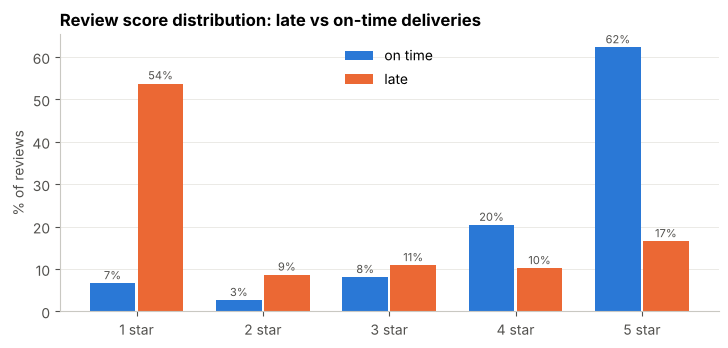

In [39]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
dist = (rev.groupby("is_late")["review_score"].value_counts(normalize=True).mul(100)
           .rename("pct").reset_index().pivot(index="review_score", columns="is_late", values="pct"))
xs = dist.index.to_numpy()
ax.bar(xs - 0.19, dist[0], width=0.36, color=BLUE, label="on time")
ax.bar(xs + 0.19, dist[1], width=0.36, color=ORANGE, label="late")
for x_, v in zip(xs, dist[1]):
    ax.text(x_ + 0.19, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=INK_2)
for x_, v in zip(xs, dist[0]):
    ax.text(x_ - 0.19, v + 1, f"{v:.0f}%", ha="center", fontsize=8, color=INK_2)
ax.set_xticks(xs, [f"{int(s)} star" for s in xs])
ax.set_ylabel("% of reviews")
ax.set_title("Review score distribution: late vs on-time deliveries")
ax.legend(loc="upper center")
ax.grid(axis="x", visible=False)
save(fig, "13_review_distribution")
plt.show()

### 4.2 Chi-square test on the 1–2 star rate
A 2×2 table: late vs on time, by 1–2 star vs 3–5 star. Besides the p-value I report the **relative risk** (how many
times more likely a late order is to get a 1–2 star review) with a 95% confidence interval.

In [40]:
table = pd.crosstab(rev["is_late"].map({0: "on time", 1: "late"}),
                    rev["low_review"].map({0: "3-5 stars", 1: "1-2 stars"})).loc[["late", "on time"], ["1-2 stars", "3-5 stars"]]
chi2, p_chi, dof_chi, expected = stats.chi2_contingency(table)   # Yates continuity correction for 2x2
(a, b), (c, d_) = table.to_numpy()
rate_late, rate_ontime = a / (a + b), c / (c + d_)
rr = rate_late / rate_ontime
se_log_rr = np.sqrt(1 / a - 1 / (a + b) + 1 / c - 1 / (c + d_))
rr_ci = np.exp(np.log(rr) + np.array([-1.96, 1.96]) * se_log_rr)
odds_ratio = (a * d_) / (b * c)
print(f"chi-square = {chi2:,.0f}, dof = {dof_chi}, p {fmt_p(p_chi)}; smallest expected count = {expected.min():,.0f}")
print(f"1-2 star rate: late {rate_late:.1%} vs on time {rate_ontime:.1%}  ->  relative risk {rr:.2f} "
      f"(95% CI {rr_ci[0]:.2f}-{rr_ci[1]:.2f}), odds ratio {odds_ratio:.2f}")
results["stats"].update({"chi2": float(chi2), "chi2_p": float(p_chi), "low_rate_late": float(rate_late),
                         "low_rate_ontime": float(rate_ontime), "relative_risk": float(rr),
                         "rr_ci": [float(rr_ci[0]), float(rr_ci[1])], "odds_ratio": float(odds_ratio)})
table

chi-square = 15,064, dof = 1, p < 1e-300; smallest expected count = 817
1-2 star rate: late 62.4% vs on time 9.3%  ->  relative risk 6.74 (95% CI 6.55-6.93), odds ratio 16.26


low_review,1-2 stars,3-5 stars
is_late,,
late,3983,2398
on time,8289,81154


### 4.3 Is it just geography? A confounding check
Late deliveries are concentrated in certain states, and those states might review differently for other reasons.
The **Mantel-Haenszel** odds ratio pools the 2×2 table within each state, so it compares late and on-time orders
*inside the same state*. If it stays close to the crude odds ratio, state is not what's driving the effect.
(This is still observational data, so it shows a robust association, not proof of causation.)

In [41]:
num_mh, den_mh, per_state = 0.0, 0.0, []
for state, g in rev.groupby("customer_state"):
    a_ = ((g.is_late == 1) & (g.low_review == 1)).sum(); b_ = ((g.is_late == 1) & (g.low_review == 0)).sum()
    c_ = ((g.is_late == 0) & (g.low_review == 1)).sum(); d2 = ((g.is_late == 0) & (g.low_review == 0)).sum()
    n_ = a_ + b_ + c_ + d2
    num_mh += a_ * d2 / n_
    den_mh += b_ * c_ / n_
    per_state.append({"state": state, "orders": n_, "late 1-2★ %": 100 * a_ / max(a_ + b_, 1),
                      "on-time 1-2★ %": 100 * c_ / max(c_ + d2, 1)})
or_mh = num_mh / den_mh
print(f"Crude odds ratio {odds_ratio:.2f} vs Mantel-Haenszel (state-adjusted) odds ratio {or_mh:.2f}")
results["stats"]["or_mantel_haenszel"] = float(or_mh)
pd.DataFrame(per_state).sort_values("orders", ascending=False).head(6).round(1)

Crude odds ratio 16.26 vs Mantel-Haenszel (state-adjusted) odds ratio 15.78


,state,orders,late 1-2★ %,on-time 1-2★ %
25,SP,40266,54.40,8.70
18,RJ,12211,73.10,10.90
10,MG,11285,59.00,9.50
22,RS,5326,64.20,8.60
17,PR,4900,52.10,9.20
23,SC,3519,59.90,8.90


### 4.4 Sample size for an A/B test of a retention offer
**Experiment:** after a customer's first order, the treatment group gets a retention offer (e.g., a discount on the
next order); control gets nothing. Randomise by `customer_unique_id`.

**Primary metric:** share of first-time customers who place a second order within 90 days (more than 1 day after
the first, so split or duplicate checkouts on the same day don't count as "coming back").

**Baseline** from history: first orders from Jan 2017 to May 2018, so every customer has a full 90-day window
before the data ends.

In [42]:
cust_orders = sql("""
SELECT c.customer_unique_id, o.order_purchase_timestamp AS ts
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.order_status NOT IN ('canceled', 'unavailable')
""")
cust_orders["ts"] = pd.to_datetime(cust_orders["ts"])
first = cust_orders.groupby("customer_unique_id")["ts"].min().rename("first_ts")
co = cust_orders.join(first, on="customer_unique_id")
later = co[(co["ts"] > co["first_ts"] + pd.Timedelta(days=1)) & (co["ts"] <= co["first_ts"] + pd.Timedelta(days=90))]
returned = first.to_frame().assign(returned_90d=lambda d: d.index.isin(later["customer_unique_id"]))
cohort = returned[(returned["first_ts"] >= "2017-01-01") & (returned["first_ts"] < "2018-06-01")]
p_base = cohort["returned_90d"].mean()
new_per_week = ((returned["first_ts"] >= "2018-01-01") & (returned["first_ts"] < "2018-09-01")).sum() / (243 / 7)
print(f"Baseline 90-day repeat rate: {p_base:.2%} ({cohort['returned_90d'].sum():,} of {len(cohort):,} first-time customers)")
print(f"New customers per week in 2018: {new_per_week:,.0f}")

Baseline 90-day repeat rate: 1.28% (980 of 76,552 first-time customers)
New customers per week in 2018: 1,488


In [43]:
# Side question: do customers whose FIRST order arrived late come back less often?
first_late = (sql("""
SELECT c.customer_unique_id, d.is_late
FROM v_order_delivery d
JOIN customers c ON c.customer_id = d.customer_id
JOIN (SELECT c2.customer_unique_id, MIN(o.order_purchase_timestamp) AS first_ts
      FROM orders o JOIN customers c2 ON c2.customer_id = o.customer_id
      WHERE o.order_status NOT IN ('canceled', 'unavailable')
      GROUP BY c2.customer_unique_id) f
  ON f.customer_unique_id = c.customer_unique_id AND f.first_ts = d.order_purchase_timestamp
""").drop_duplicates("customer_unique_id").set_index("customer_unique_id")["is_late"])
coh = cohort.join(first_late.rename("first_late"), how="inner")
ret_tab = pd.crosstab(coh["first_late"].map({0: "first order on time", 1: "first order late"}), coh["returned_90d"])
chi2_r, p_r, _, _ = stats.chi2_contingency(ret_tab)
ret_rates = coh.groupby("first_late")["returned_90d"].mean()
print(f"90-day return rate: first order on time {ret_rates[0]:.2%} vs late {ret_rates[1]:.2%} "
      f"(chi-square p = {p_r:.3f}, n late = {int(coh['first_late'].sum()):,})")
print("Lower after a late first order, but not significant at 5%: with a ~1% base rate even this many customers "
      "gives little power, which is exactly the problem the sample-size calculation below has to solve.")
results["ab_test"] = {"return_after_ontime_first": float(ret_rates[0]), "return_after_late_first": float(ret_rates[1]),
                      "return_late_vs_ontime_p": float(p_r)}

90-day return rate: first order on time 1.30% vs late 1.02% (chi-square p = 0.078, n late = 5,687)
Lower after a late first order, but not significant at 5%: with a ~1% base rate even this many customers gives little power, which is exactly the problem the sample-size calculation below has to solve.


In [44]:
def sample_size_two_proportions(p1: float, p2: float, alpha: float = 0.05, power: float = 0.80) -> int:
    """Customers per group for a two-sided two-proportion z-test."""
    z_alpha = stats.norm.ppf(1 - alpha / 2)    # 1.96 for alpha = 0.05
    z_beta = stats.norm.ppf(power)             # 0.84 for 80% power
    p_bar = (p1 + p2) / 2
    n = (z_alpha * np.sqrt(2 * p_bar * (1 - p_bar)) + z_beta * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / (p2 - p1) ** 2
    return int(np.ceil(n))


ab = []
for lift in [0.10, 0.20, 0.30, 0.50]:
    p2 = p_base * (1 + lift)
    n = sample_size_two_proportions(p_base, p2)
    ab.append({"relative lift (MDE)": f"{lift:.0%}", "control rate %": 100 * p_base, "treatment rate %": 100 * p2,
               "customers per group": n, "total customers": 2 * n, "weeks to enrol": 2 * n / new_per_week})
ab = pd.DataFrame(ab)
results["ab_test"].update({"baseline_repeat_90d": float(p_base), "new_customers_per_week": float(new_per_week),
                           "table": ab.round(2).to_dict("records")})
ab.round(2)

,relative lift (MDE),control rate %,treatment rate %,customers per group,total customers,weeks to enrol
0,10%,1.28,1.41,127022,254044,170.69
1,20%,1.28,1.54,33245,66490,44.67
2,30%,1.28,1.66,15437,30874,20.74
3,50%,1.28,1.92,6032,12064,8.11


In [45]:
# Check the formula by simulation: run 4,000 fake experiments at the 20% lift sample size
n20 = int(ab.loc[ab["relative lift (MDE)"] == "20%", "customers per group"].iloc[0])
rng = np.random.default_rng(RANDOM_STATE)
ctrl = rng.binomial(n20, p_base, 4000) / n20
treat = rng.binomial(n20, p_base * 1.2, 4000) / n20
pooled = (ctrl + treat) / 2
z = (treat - ctrl) / np.sqrt(pooled * (1 - pooled) * 2 / n20)
sim_power = np.mean(np.abs(z) > stats.norm.ppf(0.975))
null_treat = rng.binomial(n20, p_base, 4000) / n20             # no real effect: false-positive rate
pooled0 = (ctrl + null_treat) / 2
z0 = (null_treat - ctrl) / np.sqrt(pooled0 * (1 - pooled0) * 2 / n20)
sim_alpha = np.mean(np.abs(z0) > stats.norm.ppf(0.975))
print(f"n = {n20:,} per group: simulated power {sim_power:.1%} (target 80%), "
      f"simulated false-positive rate {sim_alpha:.1%} (target 5%)")
results["ab_test"].update({"n_per_group_20pct": n20, "sim_power": float(sim_power), "sim_alpha": float(sim_alpha)})

n = 33,245 per group: simulated power 79.3% (target 80%), simulated false-positive rate 4.8% (target 5%)


**What the numbers mean for the experiment**
- The base rate is tiny (~1.3%), so small lifts are expensive to detect: a 20% relative lift needs about 33k
  customers per group, roughly 45 weeks of *all* new customers. Only a large effect (50% lift, ~6k per group,
  ~8 weeks) is testable in a reasonable time. So the offer must be strong enough to plausibly move behaviour a lot,
  or the metric must be more sensitive (e.g., a 180-day window, or app visits / add-to-cart as a leading indicator).
- Fix the sample size and the 90-day window **before** starting, and don't stop early when the result looks good
  (peeking inflates false positives).
- Guardrail metrics: margin per order (the discount costs money), cancellation rate, review scores.
- The simulation confirms the formula: at the computed n, power is ~80% and the false-positive rate ~5%.

## Part 5. Text-to-SQL agent (Groq)
The agent lives in `agent/sql_agent.py` (run it from a terminal with a Groq API key). It turns a business question
into one SQLite query, runs it read-only and explains the answer. The safety layers can be tested here without
an API key.

In [46]:
sys.path.insert(0, "agent")
from sql_agent import validate_sql, connect_readonly, run_readonly_query  # noqa: E402

attempts = ["SELECT customer_state, COUNT(*) FROM v_order_delivery GROUP BY 1",
            "WITH x AS (SELECT 1 AS a) SELECT a FROM x",
            "SELECT * FROM orders WHERE order_status = 'delete'",   # keyword inside a string: allowed
            "DROP TABLE orders",
            "SELECT 1; DELETE FROM orders",
            "ATTACH DATABASE 'other.db' AS o",
            "PRAGMA table_info(orders)",
            "SELECT load_extension('evil.so')"]
pd.DataFrame([{"query": q, "allowed": validate_sql(q)[0], "reason": validate_sql(q)[1]} for q in attempts])

,query,allowed,reason
0,"SELECT customer_state, COUNT(*) FROM v_order_d...",True,ok
1,WITH x AS (SELECT 1 AS a) SELECT a FROM x,True,ok
2,SELECT * FROM orders WHERE order_status = 'del...,True,ok
3,DROP TABLE orders,False,query must start with SELECT or WITH
4,SELECT 1; DELETE FROM orders,False,only one statement is allowed
5,ATTACH DATABASE 'other.db' AS o,False,query must start with SELECT or WITH
6,PRAGMA table_info(orders),False,query must start with SELECT or WITH
7,SELECT load_extension('evil.so'),False,forbidden keyword: LOAD_EXTENSION


In [47]:
# Layers 3-4: even if the validator were bypassed, the connection itself refuses to write
ro = connect_readonly(DB_PATH)
for q in ["DELETE FROM orders", "CREATE TABLE hack(a)", "UPDATE orders SET order_status = 'x'"]:
    try:
        ro.execute(q)
        print("NOT BLOCKED:", q)
    except Exception as e:
        print(f"blocked by the database connection: {q:<40} -> {e}")
rows, truncated = run_readonly_query(ro, "SELECT * FROM orders")   # row cap
print(f"\nSELECT * FROM orders returned {len(rows)} rows (capped, truncated={truncated})")

blocked by the database connection: DELETE FROM orders                       -> not authorized
blocked by the database connection: CREATE TABLE hack(a)                     -> not authorized
blocked by the database connection: UPDATE orders SET order_status = 'x'     -> not authorized

SELECT * FROM orders returned 200 rows (capped, truncated=True)


In [48]:
# Live demo: runs only if GROQ_API_KEY is set (it isn't in the run that produced these outputs)
if os.getenv("GROQ_API_KEY"):
    from sql_agent import SQLAgent, print_result
    agent = SQLAgent(DB_PATH)
    for q in ["Which 5 states have the highest late-delivery rate among states with at least 500 delivered orders?",
              "How did monthly revenue change in 2018?",
              "What share of customers placed more than one order?"]:
        print_result(agent.ask(q))
else:
    print("GROQ_API_KEY is not set, so the live LLM demo is skipped. Run:  python agent/sql_agent.py "
          "\"your question\"   and   python agent/eval_agent.py   to measure accuracy on 12 test questions.")

GROQ_API_KEY is not set, so the live LLM demo is skipped. Run:  python agent/sql_agent.py "your question"   and   python agent/eval_agent.py   to measure accuracy on 12 test questions.


## Part 6. Recommendations with estimated impact
Every estimate uses 2018 volumes (Jan–Aug) and the numbers computed above. Assumptions are stated next to each one,
so they can be challenged and changed.

In [49]:
vol = df[(df["purchase_ts"] >= "2018-01-01") & (df["purchase_ts"] < "2018-09-01")]
months = 8
orders_pm = len(vol) / months
late_pm = vol["is_late"].sum() / months
low_gap = rate_late - rate_ontime        # extra 1-2 star share caused per late order (from 4.2)
print(f"2018 baseline: {orders_pm:,.0f} delivered orders/month, {late_pm:,.0f} late/month ({vol['is_late'].mean():.1%})")
print(f"A late order is {100 * low_gap:.0f} percentage points more likely to get a 1-2 star review "
      f"({rate_late:.0%} vs {rate_ontime:.0%})")

# R1: act on the riskiest 10% of orders at checkout
recall10 = test_results.loc[best_name, "recall@10%"]
prevent_share = 0.30                     # ASSUMPTION: expediting / seller nudges prevent 30% of flagged late orders
r1_avoided = late_pm * recall10 * prevent_share

# R2: seller hand-over SLA, using the ACTUAL purchase-to-carrier time of each order (an operational lever)
vol_h = vol.dropna(subset=["carrier_ts"]).copy()
vol_h["handling"] = (vol_h["carrier_ts"] - vol_h["purchase_ts"]).dt.total_seconds() / 86400
vol_h["handover"] = pd.cut(vol_h["handling"], [-1, 1, 2, 3, 5, 1000], labels=["<=1d", "1-2d", "2-3d", "3-5d", ">5d"])
handover = vol_h.groupby("handover", observed=True)["is_late"].agg(orders="size", late_rate="mean")
slow = vol_h["handling"] > 3
r2_avoided = (vol_h.loc[slow, "is_late"].mean() - handover.loc["2-3d", "late_rate"]) * slow.sum() / months

# R3: regional promises for states with the worst late rates
st = vol.groupby("customer_state")["is_late"].agg(orders="size", late_rate="mean")
nat_rate = vol["is_late"].mean()
hot = st[(st["orders"] >= 200) & (st["late_rate"] > 1.5 * nat_rate)].sort_values("late_rate", ascending=False)
r3_avoided = ((hot["late_rate"] - nat_rate) * hot["orders"]).sum() / months
hot_order_share = hot["orders"].sum() / len(vol)
hot_late_share = (hot["late_rate"] * hot["orders"]).sum() / vol["is_late"].sum()

# R4: retention offer, if the A/B test shows a 20% relative lift
new_pm = new_per_week * 52 / 12
extra_repeaters = new_pm * p_base * 0.20
aov = results["revenue"]["aov"]

recs = pd.DataFrame([
    {"recommendation": "1. Score every order at checkout; expedite or warn on the riskiest 10%",
     "evidence": f"top 10% of orders hold {recall10:.0%} of late deliveries (test)",
     "estimated impact / month": f"~{r1_avoided:,.0f} fewer late orders, ~{r1_avoided * low_gap:,.0f} fewer 1-2★ reviews",
     "key assumption": "interventions prevent 30% of flagged late orders"},
    {"recommendation": "2. Seller hand-over SLA: ship to carrier within 3 days",
     "evidence": f"hand-over >3 days: {vol_h.loc[slow, 'is_late'].mean():.1%} late vs {handover.loc['2-3d', 'late_rate']:.1%} at 2-3 days",
     "estimated impact / month": f"~{r2_avoided:,.0f} fewer late orders, ~{r2_avoided * low_gap:,.0f} fewer 1-2★ reviews",
     "key assumption": "slow orders reach the 2-3 day late rate"},
    {"recommendation": f"3. Region-specific promises and carriers for {', '.join(hot.index)}",
     "evidence": f"{hot_order_share:.0%} of orders but {hot_late_share:.0%} of late deliveries",
     "estimated impact / month": f"~{r3_avoided:,.0f} fewer late orders if they reach the national rate",
     "key assumption": "gap to national late rate can be closed"},
    {"recommendation": "4. Don't roll out a blanket retention discount; A/B test a strong offer first",
     "evidence": f"only {p_base:.1%} return within 90 days; a 20% lift needs ~{n20 / 1000:.0f}k customers per group",
     "estimated impact / month": f"20% lift = only ~{extra_repeaters:,.0f} extra repeat customers (~R${extra_repeaters * aov:,.0f} GMV)",
     "key assumption": "value is small unless the lift is large; discount cost not netted"},
])
results["recommendations"] = {"orders_per_month_2018": float(orders_pm), "late_per_month_2018": float(late_pm),
                              "low_review_gap": float(low_gap), "r1_avoided": float(r1_avoided),
                              "r2_avoided": float(r2_avoided), "r2_slow_late": float(vol_h.loc[slow, "is_late"].mean()),
                              "r2_23_late": float(handover.loc["2-3d", "late_rate"]), "r2_slow_share": float(slow.mean()),
                              "r3_states": list(hot.index), "r3_avoided": float(r3_avoided),
                              "r3_order_share": float(hot_order_share), "r3_late_share": float(hot_late_share),
                              "r4_extra_repeaters": float(extra_repeaters), "r4_gmv": float(extra_repeaters * aov),
                              "handover_table": handover.reset_index().astype({"handover": str}).round(4).to_dict("records")}
display(handover.assign(late_rate=lambda d: (100 * d["late_rate"]).round(1)).rename(columns={"late_rate": "late %"}))
print("Estimates 1-3 overlap (the same late order can be counted by more than one), so don't add them up.")
with pd.option_context("display.max_colwidth", 90):
    display(recs)

2018 baseline: 6,597 delivered orders/month, 510 late/month (7.7%)
A late order is 53 percentage points more likely to get a 1-2 star review (62% vs 9%)


,orders,late %
handover,,
<=1d,11611,3.60
1-2d,13885,6.00
2-3d,9027,7.60
3-5d,10076,8.20
>5d,8176,15.90


Estimates 1-3 overlap (the same late order can be counted by more than one), so don't add them up.


,recommendation,evidence,estimated impact / month,key assumption
0,1. Score every order at checkout; expedite or warn on the riskiest 10%,top 10% of orders hold 25% of late deliveries (test),"~38 fewer late orders, ~20 fewer 1-2★ reviews",interventions prevent 30% of flagged late orders
1,2. Seller hand-over SLA: ship to carrier within 3 days,hand-over >3 days: 11.7% late vs 7.6% at 2-3 days,"~92 fewer late orders, ~49 fewer 1-2★ reviews",slow orders reach the 2-3 day late rate
2,"3. Region-specific promises and carriers for MA, CE, PI, PA, MS, BA, ES, RJ",21% of orders but 40% of late deliveries,~95 fewer late orders if they reach the national rate,gap to national late rate can be closed
3,4. Don't roll out a blanket retention discount; A/B test a strong offer first,only 1.3% return within 90 days; a 20% lift needs ~33k customers per group,"20% lift = only ~17 extra repeat customers (~R$2,645 GMV)",value is small unless the lift is large; discount cost not netted


## Summary
- **Business:** GMV grew strongly year over year; health & beauty, watches & gifts and bed/bath/table lead revenue.
  Customers are almost all one-time buyers, so growth depends on acquisition.
- **Delivery:** Olist promises about twice the actual delivery time, yet ~7% of orders still arrive late, mostly in
  the North and Northeast and at sellers that are slow to hand over to the carrier.
- **Model:** a leakage-free model ranks orders well enough to concentrate late deliveries in the riskiest decile.
  A random split would have overstated the tree models' AUC; rolling time-series validation picked the model.
- **Statistics:** late orders get clearly worse reviews, and the effect holds within states. With a ~1.3% repeat
  rate, a retention test needs a large expected effect to be worth running.
- **Agent:** managers can ask questions in plain English; the database can't be modified through it.

In [50]:
RESULTS_PATH.write_text(json.dumps(results, indent=2, default=str))
con.close()
print(f"Saved key results to {RESULTS_PATH}")
print(json.dumps({k: results[k] for k in ["revenue", "delivery", "customers"]}, indent=1, default=str)[:1500])

Saved key results to results/summary.json
{
 "revenue": {
  "jan_aug_2017_gmv": 3574993.0,
  "jan_aug_2018_gmv": 8593138.0,
  "yoy_gmv_growth": 1.4036796715406155,
  "yoy_order_growth": 1.3725733534261146,
  "peak_month": "2017-11",
  "peak_gmv": 1172192.0,
  "aov": 160.19313620346253
 },
 "delivery": {
  "avg_delivery_days": 12.6,
  "avg_promised_days": 23.7,
  "late_pct": 6.77,
  "delivered_orders": 96470,
  "fastest_state": "SP",
  "fastest_days": 8.8,
  "slowest_state": "RR",
  "slowest_days": 29.4,
  "worst_late_states_1000plus": [
   {
    "state": "CE",
    "late_pct": 13.8
   },
   {
    "state": "BA",
    "late_pct": 12.2
   },
   {
    "state": "RJ",
    "late_pct": 12.1
   }
  ]
 },
 "customers": {
  "unique_customers": 94990,
  "repeat_pct": 3.0400000000000063
 }
}
